#### Notebook 05 — Validation, Sensitivity Analysis & Methodological Robustness

Notebook 04 established a way to identify potential persistent changes in subscribers' nighttime locations. Notebook 05 must now establish how reliable those findings are, how sensitive they are to analytical assumptions, and when the methodology should abstain from making an inference.


##### 1. Notebook objective and assumptions
#### Objective

Evaluate the reliability, robustness and generalisability of the residential
location inference and population mobility methodology developed in
Notebooks 02, 03 and 04.

#### Key analytical objectives

1. Evaluate temporal stability using separate inference and holdout periods.
2. Assess sensitivity to alternative nighttime observation windows.
3. Quantify the impact of minimum observation thresholds.
4. Evaluate sensitivity to geographic movement and persistence thresholds.
5. Compare DBSCAN spatial clustering with dominant-cell aggregation.
6. Assess confidence scores against available synthetic reference labels.
7. Investigate the impact of sparse observations and coordinate quality.
8. Identify parameter configurations that provide a reasonable balance
   between inference coverage and reliability.

#### Validation principles

- Temporal consistency is not equivalent to geographic accuracy.
- Synthetic reference labels are used only for evaluation.
- Simulator-generated labels must never be used as inference features.
- No estimate is preferable to an unsupported residential location.
- Confidence scores are not probabilities unless calibration supports
  that interpretation.
- All thresholds are exploratory and require empirical justification.
- Subscriber-level validation outputs remain private.

#### Dataset limitations

The dataset covers February 2026 and contains synthetic CDR/IPDR records.
The available temporal holdout is limited to the observation period.
The results should not be interpreted as independent validation using
real MNO ground truth.

#### 2. Imports, configuration and project paths

In [279]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.calibration import calibration_curve
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

# PROJECT PATHS
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw"

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed"

NOTEBOOK02_OUTPUT = PROCESSED_PATH / "notebook_02"

NOTEBOOK03_OUTPUT = PROCESSED_PATH / "notebook_03"

NOTEBOOK04_OUTPUT = PROCESSED_PATH / "notebook_04"

NOTEBOOK05_OUTPUT = PROCESSED_PATH / "notebook_05"

NOTEBOOK05_OUTPUT.mkdir(parents=True, exist_ok=True)

# INPUT FILES
DATA_FILE = (
    RAW_PATH / "MPD_sample_synthetic_ken_3000subs_full.csv"
)

CELL_VALIDATION_FILE = (
    NOTEBOOK02_OUTPUT / "cell_coordinate_validation.csv"
)

SUBSCRIBER_CLASSIFICATION_FILE = (
    NOTEBOOK02_OUTPUT / "subscriber_classification.csv"
)

HOME_ESTIMATES_FILE = (
    NOTEBOOK02_OUTPUT / "home_location_estimates.csv"
)

# GENERAL CONFIGURATION
EARTH_RADIUS_KM = 6371.0088

NIGHT_START_HOUR = 20
NIGHT_END_HOUR = 6

BASELINE_START = pd.Timestamp("2026-02-01")
HOLDOUT_START = pd.Timestamp("2026-02-15")
ANALYSIS_END = pd.Timestamp("2026-02-28")

# Initial reference configuration.
BASELINE_MIN_NIGHTS = 5
FOLLOWUP_MIN_NIGHTS = 5

MIN_FLOW_SUBSCRIBERS = 5

MOVEMENT_DISTANCE_KM = 5.0

MIN_DOMINANT_SHARE = 0.40

MIN_DESTINATION_NIGHTS = 5

MIN_ACTIVE_WEEKS = 2

# DBSCAN parameters from Notebook 02.
DBSCAN_EPS_KM = 1.0
DBSCAN_MIN_SAMPLES = 2

print("Project root:", PROJECT_ROOT)
print("Notebook 05 output:", NOTEBOOK05_OUTPUT)

Project root: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference
Notebook 05 output: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_05


#### 3. Load and validate the data

In [280]:
# CHECK INPUT FILES
required_files = [
    DATA_FILE,
    CELL_VALIDATION_FILE,
    SUBSCRIBER_CLASSIFICATION_FILE
]

missing_files = [
    file for file in required_files
    if not file.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(str(f) for f in missing_files)
    )

# LOAD DATA
df = pd.read_csv(
    DATA_FILE,
    dtype={
        "msisdn": "string",
        "cell_id": "string",
        "latitude": "float64",
        "longitude": "float64",
        "data_type": "category",
        "service": "category",
        "location_target": "category",
        "location_place": "category",
        "profile": "category",
        "record_profile": "category",
        "movement_profile": "category"
    },
    low_memory=False
)

cell_validation = pd.read_csv(
    CELL_VALIDATION_FILE,
    dtype={"cell_id": "string"}
)

subscriber_flags = pd.read_csv(
    SUBSCRIBER_CLASSIFICATION_FILE,
    dtype={"msisdn": "string"}
)

# VALIDATE SCHEMA
required_event_columns = [
    "msisdn",
    "datetime",
    "cell_id",
    "latitude",
    "longitude"
]

required_cell_columns = [
    "cell_id",
    "coordinate_quality_flag"
]

required_subscriber_columns = [
    "msisdn",
    "subscriber_type"
]

def validate_columns(data, required_columns, name):

    missing = set(required_columns) - set(data.columns)

    if missing:
        raise ValueError(
            f"{name} is missing columns: {sorted(missing)}"
        )


validate_columns(
    df,
    required_event_columns,
    "Raw events"
)

validate_columns(
    cell_validation,
    required_cell_columns,
    "Cell validation"
)

validate_columns(
    subscriber_flags,
    required_subscriber_columns,
    "Subscriber classification"
)

assert subscriber_flags["msisdn"].is_unique
assert cell_validation["cell_id"].is_unique

df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)

df["latitude"] = pd.to_numeric(
    df["latitude"],
    errors="coerce"
)

df["longitude"] = pd.to_numeric(
    df["longitude"],
    errors="coerce"
)

print("Raw dataset:", df.shape)
print("Unique subscribers:", df["msisdn"].nunique())
print("Unique cells:", df["cell_id"].nunique())

Raw dataset: (1072608, 16)
Unique subscribers: 3000
Unique cells: 35956


#### 4. Prepare the validated nighttime dataset

In [281]:
# use ordinary subscribers and cells classified as having acceptable coordinates
# ORDINARY SUBSCRIBERS
ordinary_ids = set(
    subscriber_flags.loc[
        subscriber_flags["subscriber_type"] == "ordinary",
        "msisdn"
    ]
)

df = df[
    df["msisdn"].isin(ordinary_ids)
].copy()

# VALID CELL COORDINATES
valid_cells = set(
    cell_validation.loc[
        cell_validation["coordinate_quality_flag"] == "acceptable",
        "cell_id"
    ]
)

df = df[
    df["cell_id"].isin(valid_cells)
].copy()


# Remove invalid records.
df = df.dropna(
    subset=[
        "msisdn",
        "datetime",
        "cell_id",
        "latitude",
        "longitude"
    ]
).copy()


# Remove geographically invalid coordinates.
df = df[
    df["latitude"].between(-90, 90)
    &
    df["longitude"].between(-180, 180)
].copy()


print("Validated events:", len(df))
print("Retained subscribers:", df["msisdn"].nunique())
print("Retained cells:", df["cell_id"].nunique())

Validated events: 416243
Retained subscribers: 2813
Retained cells: 24986


In [282]:
# Create the reusable nighttime preparation function
# NIGHTTIME WINDOW FUNCTION
def prepare_nighttime_events(
    data,
    start_hour=20,
    end_hour=6
):

    result = data.copy()

    hours = result["datetime"].dt.hour

    if start_hour > end_hour:

        result = result[
            (hours >= start_hour)
            |
            (hours < end_hour)
        ].copy()

    else:

        result = result[
            (hours >= start_hour)
            &
            (hours < end_hour)
        ].copy()

    # Assign after-midnight records to the previous night.
    result["night_id"] = (
        result["datetime"]
        - pd.to_timedelta(end_hour, unit="h")
    ).dt.normalize()

    return result

In [283]:
# Use the original 20:00–06:00 window

night_events = prepare_nighttime_events(
    df,
    start_hour=NIGHT_START_HOUR,
    end_hour=NIGHT_END_HOUR
)


print("Nighttime events:", len(night_events))

print("Nighttime subscribers:", night_events["msisdn"].nunique())

print(
    "Nighttime date range:",
    night_events["night_id"].min(),
    "to",
    night_events["night_id"].max()
)

Nighttime events: 69517
Nighttime subscribers: 2758
Nighttime date range: 2026-01-31 00:00:00 to 2026-02-28 00:00:00


#### 5. Create reusable geographic functions

In [284]:
# HAVERSINE DISTANCE
def haversine_km(lat1, lon1, lat2, lon2):

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        +
        np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

    return EARTH_RADIUS_KM * c

# GEOGRAPHIC CENTROID
def geographic_centroid(data):

    return pd.Series({
        "latitude": data["latitude"].median(),
        "longitude": data["longitude"].median()
    })

In [285]:
# DOMINANT NIGHTTIME LOCATION INFERENCE
def infer_dominant_locations(
    events,
    min_nights=5
):

    subscriber_cell_nights = (
        events[
            [
                "msisdn",
                "cell_id",
                "night_id",
                "latitude",
                "longitude"
            ]
        ]
        .drop_duplicates(
            subset=[
                "msisdn",
                "cell_id",
                "night_id"
            ]
        )
        .copy()
    )

    if subscriber_cell_nights.empty:
        return pd.DataFrame()

    # Count distinct nights at each cell.
    cell_counts = (
        subscriber_cell_nights.groupby(
            [
                "msisdn",
                "cell_id"
            ],
            observed=True
        )
        .agg(
            nights_at_cell=("night_id", "nunique"),
            latitude=("latitude", "median"),
            longitude=("longitude", "median")
        )
        .reset_index()
    )

    # Total observed nights per subscriber.
    total_nights = (
        subscriber_cell_nights.groupby("msisdn")
        .agg(
            observed_nights=("night_id", "nunique")
        )
        .reset_index()
    )

    # Deterministic ranking.
    cell_counts = cell_counts.sort_values(
        [
            "msisdn",
            "nights_at_cell",
            "cell_id"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )

    dominant = (
        cell_counts
        .drop_duplicates("msisdn")
        .copy()
    )

    dominant = dominant.merge(
        total_nights,
        on="msisdn",
        how="left",
        validate="one_to_one"
    )

    dominant["dominance_share"] = (
        dominant["nights_at_cell"]
        / dominant["observed_nights"]
    )

    # Only return subscribers meeting the observation threshold.
    dominant = dominant[
        dominant["observed_nights"] >= min_nights
    ].copy()

    return dominant.rename(
        columns={
            "cell_id": "dominant_cell",
            "nights_at_cell": "dominant_nights",
            "latitude": "dominant_latitude",
            "longitude": "dominant_longitude"
        }
    )

#### 6. Experiment 1 — Temporal holdout validation

Infer each subscriber's dominant nighttime location using February 1–14, then compare it with the dominant location observed during February 15–28.

This tests whether the inferred location is temporally consistent.

It does not establish that the inferred location is the subscriber's true residence.

In [286]:
# TEMPORAL HOLDOUT SPLIT

inference_events = night_events[
    night_events["night_id"].between(
        BASELINE_START,
        HOLDOUT_START - pd.Timedelta(days=1)
    )
].copy()


holdout_events = night_events[
    night_events["night_id"].between(
        HOLDOUT_START,
        ANALYSIS_END
    )
].copy()


print("Inference period:", inference_events["night_id"].min(),
      "to", inference_events["night_id"].max())

print("Holdout period:", holdout_events["night_id"].min(),
      "to", holdout_events["night_id"].max())

print("Inference events:", len(inference_events))

print("Holdout events:", len(holdout_events))

Inference period: 2026-02-01 00:00:00 to 2026-02-14 00:00:00
Holdout period: 2026-02-15 00:00:00 to 2026-02-28 00:00:00
Inference events: 34983
Holdout events: 33941


In [287]:
# Infer locations separately
# INFERENCE PERIOD LOCATION
inference_locations = infer_dominant_locations(
    inference_events,
    min_nights=BASELINE_MIN_NIGHTS
)


inference_locations = inference_locations.rename(
    columns={
        "dominant_cell": "inference_dominant_cell",
        "dominant_latitude": "inference_latitude",
        "dominant_longitude": "inference_longitude",
        "observed_nights": "inference_observed_nights",
        "dominance_share": "inference_dominance"
    }
)

# HOLDOUT PERIOD LOCATION
holdout_locations = infer_dominant_locations(
    holdout_events,
    min_nights=FOLLOWUP_MIN_NIGHTS
)


holdout_locations = holdout_locations.rename(
    columns={
        "dominant_cell": "holdout_dominant_cell",
        "dominant_latitude": "holdout_latitude",
        "dominant_longitude": "holdout_longitude",
        "observed_nights": "holdout_observed_nights",
        "dominance_share": "holdout_dominance"
    }
)

In [288]:
# Compare the two periods
# TEMPORAL HOLDOUT COMPARISON

temporal_holdout = inference_locations.merge(
    holdout_locations,
    on="msisdn",
    how="inner",
    validate="one_to_one"
)


temporal_holdout["holdout_geographic_error_km"] = (
    haversine_km(
        temporal_holdout["inference_latitude"],
        temporal_holdout["inference_longitude"],
        temporal_holdout["holdout_latitude"],
        temporal_holdout["holdout_longitude"]
    )
)

temporal_holdout["within_1km"] = (
    temporal_holdout["holdout_geographic_error_km"] <= 1
)

temporal_holdout["within_2km"] = (
    temporal_holdout["holdout_geographic_error_km"] <= 2
)

temporal_holdout["within_5km"] = (
    temporal_holdout["holdout_geographic_error_km"] <= 5
)


print(
    "Subscribers evaluated:",
    temporal_holdout["msisdn"].nunique()
)

display(temporal_holdout.head())

Subscribers evaluated: 1114


,msisdn,inference_dominant_cell,dominant_nights_x,inference_latitude,inference_longitude,inference_observed_nights,inference_dominance,holdout_dominant_cell,dominant_nights_y,holdout_latitude,holdout_longitude,holdout_observed_nights,holdout_dominance,holdout_geographic_error_km,within_1km,within_2km,within_5km
0,subscribers_00002,28284,3,-1.220,36.887,6,0.500,22951,7,-1.319,36.862,10,0.700,11.429,False,False,False
1,subscribers_00003,18804,11,-1.274,36.837,14,0.786,18804,11,-1.274,36.837,12,0.917,0.000,True,True,True
2,subscribers_00005,13984,1,-1.289,36.816,5,0.200,15009,1,-1.323,36.820,7,0.143,3.807,False,False,True
3,subscribers_00007,28155,13,-1.191,36.887,13,1.000,28155,11,-1.191,36.887,12,0.917,0.000,True,True,True
4,subscribers_00008,2047,6,-1.248,36.664,8,0.750,2047,6,-1.248,36.664,7,0.857,0.000,True,True,True


In [289]:
# Calculate the temporal consistency metrics
# TEMPORAL HOLDOUT METRICS

temporal_holdout_metrics = pd.DataFrame({
    "metric": [
        "Subscribers evaluated",
        "Median geographic difference (km)",
        "Mean geographic difference (km)",
        "90th percentile geographic difference (km)",
        "Within 1 km",
        "Within 2 km",
        "Within 5 km"
    ],
    "value": [
        len(temporal_holdout),
        temporal_holdout["holdout_geographic_error_km"].median(),
        temporal_holdout["holdout_geographic_error_km"].mean(),
        temporal_holdout["holdout_geographic_error_km"].quantile(0.90),
        temporal_holdout["within_1km"].mean() * 100,
        temporal_holdout["within_2km"].mean() * 100,
        temporal_holdout["within_5km"].mean() * 100
    ]
})


display(temporal_holdout_metrics)

,metric,value
0,Subscribers evaluated,"1,114.000"
1,Median geographic difference (km),0.000
2,Mean geographic difference (km),1.644
3,90th percentile geographic difference (km),5.962
4,Within 1 km,78.636
5,Within 2 km,80.790
6,Within 5 km,88.241


### Interpretation and Summary

The temporal holdout comparison evaluates how consistently inferred residential locations match locations identified during a separate holdout period. A smaller geographic error indicates better location consistency.

**Key observations:**

- **Subscribers evaluated:** 1,114.
- **Within 1 km:** 876 subscribers (78.64%).
- **Within 2 km:** 900 subscribers (80.79%).
- **Within 5 km:** 983 subscribers (88.24%).
- **Mean geographic error:** 1.64 km.
- **Median geographic error:** 0 km.
- **95th percentile error:** 9.82 km.
- **Maximum geographic error:** 52.07 km.

**Key takeaway:**

The results indicate strong temporal consistency in inferred residential locations. Approximately 88% of subscribers have holdout locations within 5 km of their original inferred locations. The median error of zero suggests that at least half of the subscribers retained exactly matching geographic coordinates across both periods.

However, a small proportion exhibit substantial geographic differences, with 16 subscribers recording errors exceeding 20 km.

**Conclusion:** The residential inference approach demonstrates promising temporal stability, with 88.24% of evaluated subscribers achieving geographic consistency within 5 km. This provides encouraging evidence that the inferred home locations generalise across separate observation periods, although larger errors warrant further investigation.

In [290]:
# Export Report
temporal_holdout.to_csv(
    NOTEBOOK05_OUTPUT / "temporal_holdout_comparison.csv",
    index=False
)

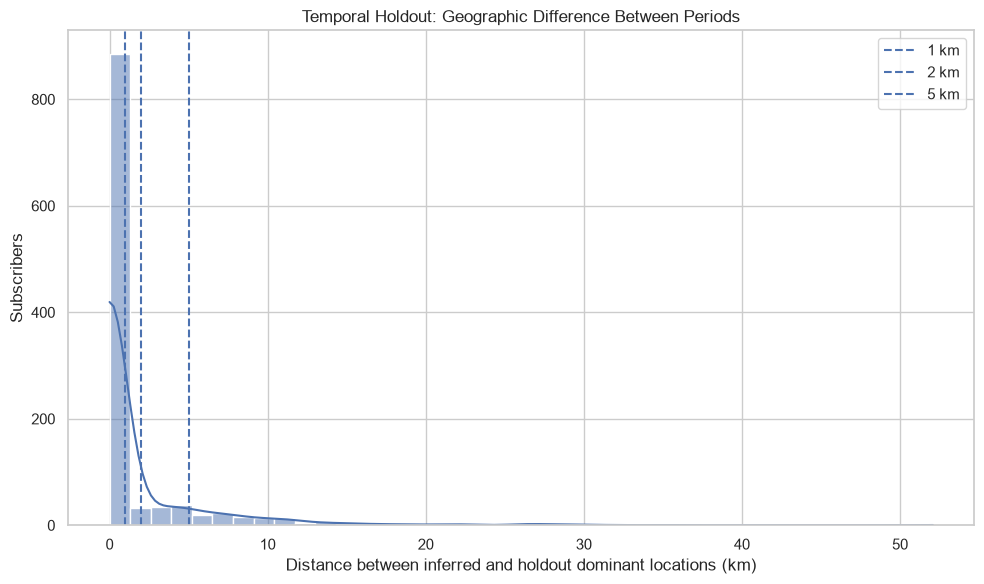

In [291]:
# Visualise the holdout error distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    temporal_holdout["holdout_geographic_error_km"],
    bins=40,
    kde=True
)

plt.axvline(
    1,
    linestyle="--",
    label="1 km"
)

plt.axvline(
    2,
    linestyle="--",
    label="2 km"
)

plt.axvline(
    5,
    linestyle="--",
    label="5 km"
)

plt.title("Temporal Holdout: Geographic Difference Between Periods")

plt.xlabel("Distance between inferred and holdout dominant locations (km)")

plt.ylabel("Subscribers")

plt.legend()

plt.tight_layout()

plt.show()

### Interpretation and Summary

The histogram shows the distribution of geographic differences between inferred residential locations and holdout-period locations.

**Key observations:**

- The distribution is heavily concentrated around **0–1 km**, indicating strong consistency between the two periods.
- Most subscribers have geographic errors below **2 km**.
- The majority fall within the **5 km tolerance threshold**.
- A small proportion of subscribers have larger geographic discrepancies, creating a long right-hand tail.
- A few extreme cases exhibit differences exceeding 20 km, with the maximum reaching approximately 52 km.

**Key takeaway:**

The concentration of observations around zero suggests that inferred residential locations are generally stable across independent observation periods. However, the long tail indicates that some subscribers experience substantial geographic variation.

**Conclusion:** The temporal holdout results provide encouraging evidence of the robustness of the residential inference approach. Most inferred locations remain geographically consistent across periods.

In [292]:
# Check whether temporal consistency varies with evidence strength

temporal_holdout["inference_evidence_group"] = pd.cut(
    temporal_holdout["inference_observed_nights"],
    bins=[0, 4, 6, 9, 14],
    labels=[
        "5-6 nights",
        "7-9 nights",
        "10-12 nights",
        "13-14 nights"
    ],
    include_lowest=True
)

temporal_consistency_by_evidence = (
    temporal_holdout.groupby(
        "inference_evidence_group",
        observed=True
    )
    .agg(
        subscribers=("msisdn", "nunique"),
        median_error_km=(
            "holdout_geographic_error_km",
            "median"
        ),
        within_2km=("within_2km", "mean")
    )
    .reset_index()
)

temporal_consistency_by_evidence["within_2km_pct"] = (
    temporal_consistency_by_evidence["within_2km"] * 100
)

display(temporal_consistency_by_evidence)

,inference_evidence_group,subscribers,median_error_km,within_2km,within_2km_pct
0,7-9 nights,194,2.992,0.423,42.268
1,10-12 nights,260,0.000,0.688,68.846
2,13-14 nights,660,0.000,0.968,96.818


### Interpretation and Summary

The results show a clear relationship between the amount of nighttime observation evidence and the temporal consistency of inferred residential locations.

**Key observations:**

- **7–9 nights:** 194 subscribers, with only 42.27% achieving location consistency within 2 km. Median geographic error is 2.99 km.
- **10–12 nights:** 260 subscribers, with 68.85% within 2 km. Median geographic error drops to 0 km.
- **13–14 nights:** 660 subscribers, with 96.82% within 2 km. Median geographic error is also 0 km.

**Key takeaway:**

Temporal consistency improves substantially as the number of nighttime observations increases. Subscribers with 13–14 nights of evidence demonstrate considerably more reliable residential location estimates than those with fewer observations.

**Conclusion:** The 13–14-night evidence group provides the strongest temporal validation, achieving 96.82% geographic consistency within 2 km. This suggests that requiring more nighttime observations can significantly improve residential inference reliability.

#### 7. Experiment 2 — Nighttime window sensitivity

Previous notebooks used 20:00–06:00. Test alternative windows to see whether inferred locations change materially.

The alternatives are:
- 19:00–05:00
- 20:00–06:00
- 21:00–05:00
- 22:00–06:00

In [293]:
# NIGHTTIME WINDOW SENSITIVITY
night_windows = [
    (19, 5),
    (20, 6),
    (21, 5),
    (22, 6)
]

window_results = []

window_location_results = {}


for start_hour, end_hour in night_windows:

    temp_nights = prepare_nighttime_events(
        df,
        start_hour=start_hour,
        end_hour=end_hour
    )

    temp_baseline = temp_nights[
        temp_nights["night_id"].between(
            BASELINE_START,
            HOLDOUT_START - pd.Timedelta(days=1)
        )
    ]

    temp_followup = temp_nights[
        temp_nights["night_id"].between(
            HOLDOUT_START,
            ANALYSIS_END
        )
    ]

    baseline_result = infer_dominant_locations(
        temp_baseline,
        min_nights=BASELINE_MIN_NIGHTS
    )

    followup_result = infer_dominant_locations(
        temp_followup,
        min_nights=FOLLOWUP_MIN_NIGHTS
    )

    baseline_result = baseline_result.rename(
        columns={
            "dominant_cell": "baseline_cell",
            "dominant_latitude": "baseline_latitude",
            "dominant_longitude": "baseline_longitude",
            "observed_nights": "baseline_nights",
            "dominance_share": "baseline_dominance"
        }
    )

    followup_result = followup_result.rename(
        columns={
            "dominant_cell": "followup_cell",
            "dominant_latitude": "followup_latitude",
            "dominant_longitude": "followup_longitude",
            "observed_nights": "followup_nights",
            "dominance_share": "followup_dominance"
        }
    )

    comparison = baseline_result.merge(
        followup_result,
        on="msisdn",
        how="inner"
    )

    if not comparison.empty:

        comparison["distance_km"] = haversine_km(
            comparison["baseline_latitude"],
            comparison["baseline_longitude"],
            comparison["followup_latitude"],
            comparison["followup_longitude"]
        )

        comparison["meaningful_shift"] = (
            comparison["distance_km"]
            >= MOVEMENT_DISTANCE_KM
        )

    else:

        comparison["distance_km"] = pd.Series(dtype=float)

        comparison["meaningful_shift"] = pd.Series(dtype=bool)

    window_name = f"{start_hour:02d}:00-{end_hour:02d}:00"

    window_location_results[window_name] = comparison

    window_results.append({
        "night_window": window_name,
        "baseline_subscribers": baseline_result["msisdn"].nunique(),
        "followup_subscribers": followup_result["msisdn"].nunique(),
        "subscribers_in_both_periods": comparison["msisdn"].nunique(),
        "median_location_change_km": (
            comparison["distance_km"].median()
            if not comparison.empty else np.nan
        ),
        "subscribers_with_5km_shift": (
            comparison["meaningful_shift"].sum()
            if not comparison.empty else 0
        ),
        "percentage_with_5km_shift": (
            comparison["meaningful_shift"].mean() * 100
            if not comparison.empty else np.nan
        )
    })


night_window_sensitivity = pd.DataFrame(window_results)

display(night_window_sensitivity)

,night_window,baseline_subscribers,followup_subscribers,subscribers_in_both_periods,median_location_change_km,subscribers_with_5km_shift,percentage_with_5km_shift
0,19:00-05:00,1714,1730,1415,0.000,234,16.537
1,20:00-06:00,1423,1372,1114,0.000,131,11.759
2,21:00-05:00,1187,1138,926,0.000,99,10.691
3,22:00-06:00,925,859,704,0.000,63,8.949


### Interpretation and Summary

The nighttime window sensitivity analysis examines whether changing the definition of nighttime affects subscriber coverage and inferred geographic movement.

**Key observations:**

- **19:00–05:00:** Highest coverage, with 1,415 subscribers observed in both periods. It also records the highest movement rate, with 16.54% experiencing shifts of at least 5 km.
- **20:00–06:00:** 1,114 subscribers observed in both periods, with 11.76% recording significant geographic shifts.
- **21:00–05:00:** 926 subscribers observed in both periods, with 10.69% recording shifts of at least 5 km.
- **22:00–06:00:** Lowest coverage, with 704 subscribers observed in both periods and 8.95% recording significant shifts.

**Key takeaway:**

The inferred movement patterns are sensitive to the definition of nighttime. Earlier nighttime windows capture more subscribers and identify a higher proportion of geographic shifts. Across all four windows, the median location change remains 0 km, suggesting that most subscribers retain their dominant nighttime location.

**Conclusion:** The 19:00–05:00 window provides the greatest subscriber coverage but also identifies more potential movement. The 20:00–06:00 window offers a reasonable alternative for sensitivity analysis.

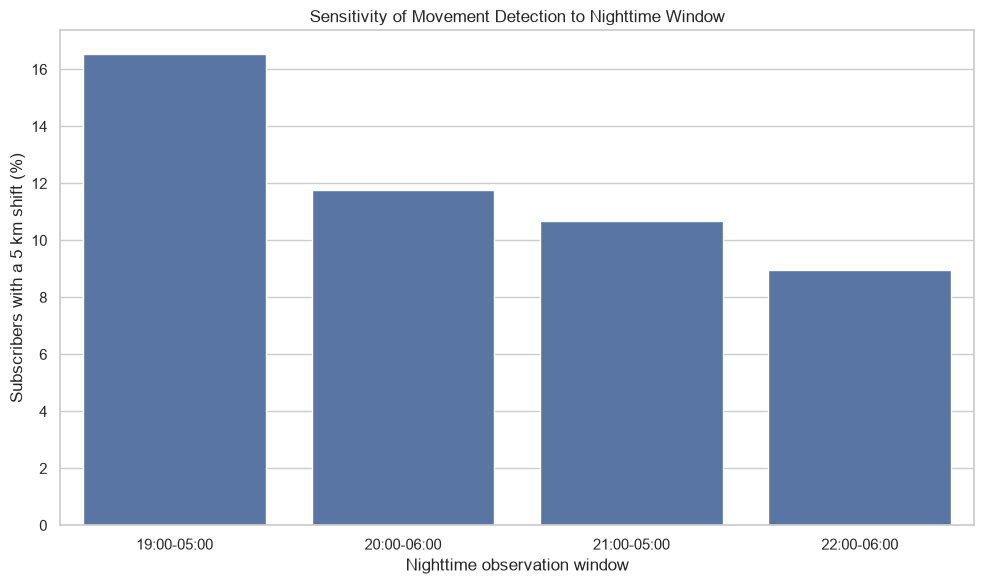

In [294]:
# Visualise the effect of nighttime window selection

plt.figure(figsize=(10, 6))

sns.barplot(
    data=night_window_sensitivity,
    x="night_window",
    y="percentage_with_5km_shift"
)

plt.title("Sensitivity of Movement Detection to Nighttime Window")

plt.xlabel("Nighttime observation window")

plt.ylabel("Subscribers with a 5 km shift (%)")

plt.tight_layout()

plt.show()

In [295]:
# Compare subscribers across the different windows
# Use the original 20:00–06:00 window as the reference.

reference_window = "20:00-06:00"

reference_results = window_location_results[reference_window][
    [
        "msisdn",
        "baseline_latitude",
        "baseline_longitude"
    ]
].rename(
    columns={
        "baseline_latitude": "reference_latitude",
        "baseline_longitude": "reference_longitude"
    }
)


window_agreement = []

for window_name, result in window_location_results.items():

    comparison = reference_results.merge(
        result[
            [
                "msisdn",
                "baseline_latitude",
                "baseline_longitude"
            ]
        ],
        on="msisdn",
        how="inner"
    )

    if comparison.empty:
        continue

    comparison["difference_km"] = haversine_km(
        comparison["reference_latitude"],
        comparison["reference_longitude"],
        comparison["baseline_latitude"],
        comparison["baseline_longitude"]
    )

    window_agreement.append({
        "night_window": window_name,
        "subscribers_compared": len(comparison),
        "median_difference_km": comparison["difference_km"].median(),
        "within_1km_pct": (
            comparison["difference_km"] <= 1
        ).mean() * 100,
        "within_2km_pct": (
            comparison["difference_km"] <= 2
        ).mean() * 100
    })


window_agreement = pd.DataFrame(window_agreement)

display(window_agreement)

,night_window,subscribers_compared,median_difference_km,within_1km_pct,within_2km_pct
0,19:00-05:00,1111,0.000,95.500,95.950
1,20:00-06:00,1114,0.000,100.000,100.000
2,21:00-05:00,926,0.000,98.272,98.596
3,22:00-06:00,704,0.000,96.449,97.017


### Interpretation and Summary

The analysis compares inferred baseline residential locations across different nighttime windows, using 20:00–06:00 as the reference.

**Key observations:**

- **19:00–05:00:** 1,111 subscribers compared, with 95.50% of inferred locations within 1 km and 95.95% within 2 km of the reference.
- **20:00–06:00:** 1,114 subscribers, with 100% agreement within both 1 km and 2 km. This is the reference window.
- **21:00–05:00:** 926 subscribers, with 98.27% within 1 km and 98.60% within 2 km.
- **22:00–06:00:** 704 subscribers, with 96.45% within 1 km and 97.02% within 2 km.

**Key takeaway:**

Residential location estimates remain highly consistent across different nighttime definitions. All alternative windows achieve at least 95.5% agreement within 1 km of the reference. The median geographic difference is 0 km across all windows.

**Conclusion:** The residential inference approach demonstrates strong robustness to changes in nighttime definitions. The 20:00–06:00 window remains a reasonable primary choice, providing strong subscriber coverage and consistent location estimates across alternative nighttime windows.

#### 8. Experiment 3 — Observation and movement threshold sensitivity

Notebook 04 used five observed nights, 40% dominant-location share and a 5 km movement threshold.

Test whether the number of detected movement signals changes substantially when these assumptions change.

In [296]:
# PRECOMPUTE PERIOD LOCATIONS

baseline_all = infer_dominant_locations(
    inference_events,
    min_nights=1
)

followup_all = infer_dominant_locations(
    holdout_events,
    min_nights=1
)


baseline_all = baseline_all.rename(
    columns={
        "dominant_cell": "baseline_cell",
        "dominant_latitude": "baseline_latitude",
        "dominant_longitude": "baseline_longitude",
        "dominant_nights": "baseline_dominant_nights",
        "observed_nights": "baseline_observed_nights",
        "dominance_share": "baseline_dominance"
    }
)


followup_all = followup_all.rename(
    columns={
        "dominant_cell": "followup_cell",
        "dominant_latitude": "followup_latitude",
        "dominant_longitude": "followup_longitude",
        "dominant_nights": "followup_dominant_nights",
        "observed_nights": "followup_observed_nights",
        "dominance_share": "followup_dominance"
    }
)


threshold_population = baseline_all.merge(
    followup_all,
    on="msisdn",
    how="inner",
    validate="one_to_one"
)


threshold_population["distance_km"] = haversine_km(
    threshold_population["baseline_latitude"],
    threshold_population["baseline_longitude"],
    threshold_population["followup_latitude"],
    threshold_population["followup_longitude"]
)


print("Subscribers available for threshold experiments:",
      len(threshold_population))

Subscribers available for threshold experiments: 2538


In [297]:
# PARAMETER SENSITIVITY GRID
minimum_night_values = [3, 5, 7, 10]

dominance_values = [0.30, 0.40, 0.50, 0.60]

movement_distance_values = [3, 5, 10, 15]

sensitivity_results = []


for min_nights in minimum_night_values:

    for min_dominance in dominance_values:

        for min_distance in movement_distance_values:

            eligible = threshold_population[
                (
                    threshold_population["baseline_observed_nights"]
                    >= min_nights
                )
                &
                (
                    threshold_population["followup_observed_nights"]
                    >= min_nights
                )
            ].copy()

            candidates = eligible[
                (
                    eligible["baseline_dominance"]
                    >= min_dominance
                )
                &
                (
                    eligible["followup_dominance"]
                    >= min_dominance
                )
                &
                (
                    eligible["distance_km"]
                    >= min_distance
                )
            ]

            sensitivity_results.append({
                "minimum_observed_nights": min_nights,
                "minimum_dominance": min_dominance,
                "movement_threshold_km": min_distance,
                "eligible_subscribers": len(eligible),
                "movement_candidates": len(candidates),
                "candidate_rate_pct": (
                    len(candidates) / len(eligible) * 100
                    if len(eligible) else np.nan
                )
            })


parameter_sensitivity = pd.DataFrame(
    sensitivity_results
)


display(
    parameter_sensitivity.sort_values(
        [
            "minimum_observed_nights",
            "minimum_dominance",
            "movement_threshold_km"
        ]
    )
)

,minimum_observed_nights,minimum_dominance,movement_threshold_km,eligible_subscribers,movement_candidates,candidate_rate_pct
0,3,0.300,3,1749,48,2.744
1,3,0.300,5,1749,30,1.715
2,3,0.300,10,1749,13,0.743
3,3,0.300,15,1749,3,0.172
4,3,0.400,3,1749,5,0.286
5,3,0.400,5,1749,3,0.172
6,3,0.400,10,1749,1,0.057
7,3,0.400,15,1749,0,0.000
8,3,0.500,3,1749,5,0.286
9,3,0.500,5,1749,3,0.172


### Interpretation and Summary

The parameter sensitivity analysis evaluates how changes in three key parameters affect the number of subscribers classified as potential movement candidates.

**Parameters tested:**

- **Minimum observed nights:** 3, 5, 7 and 10 nights.
- **Minimum location dominance:** 30%, 40%, 50% and 60%.
- **Movement distance threshold:** 3 km, 5 km, 10 km and 15 km.

This produces **64 parameter combinations**, allowing the analysis to assess how sensitive movement estimates are to different classification requirements.

**Expected patterns:**

- Increasing minimum observed nights reduces the eligible subscriber population but improves observation reliability.
- Increasing location dominance makes the classification stricter by requiring stronger evidence of a dominant location.
- Increasing the movement distance threshold reduces the number of subscribers classified as movement candidates.
- Lower thresholds increase candidate counts but may introduce less reliable movement signals.

**Key takeaway:**

The analysis helps identify whether potential displacement estimates remain consistent under different parameter settings or are heavily dependent on specific thresholds.

In [298]:
# Export Report
parameter_sensitivity.to_csv(
    NOTEBOOK05_OUTPUT / "parameter_sensitivity.csv",
    index=False
)

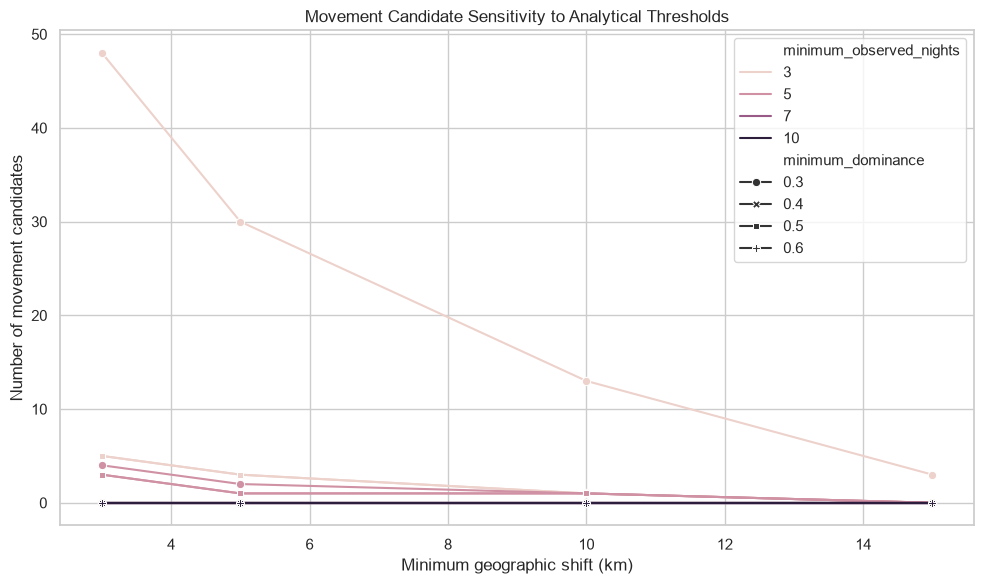

In [299]:
# Visualise the effect of the movement threshold

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=parameter_sensitivity,
    x="movement_threshold_km",
    y="movement_candidates",
    hue="minimum_observed_nights",
    style="minimum_dominance",
    markers=True,
    dashes=False
)

plt.title("Movement Candidate Sensitivity to Analytical Thresholds")

plt.xlabel("Minimum geographic shift (km)")

plt.ylabel("Number of movement candidates")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The chart shows how the number of potential movement candidates changes as the minimum geographic shift threshold increases under different observation and location-dominance requirements.

**Key observations:**

- **Movement distance has the strongest influence:** Increasing the threshold from 3 km to 15 km substantially reduces the number of candidates.
- **Minimum observed nights:** Requiring more nighttime observations reduces candidate counts, as fewer subscribers meet the eligibility criteria.
- **Location dominance:** Higher dominance requirements (40%–60%) produce fewer candidates than the less restrictive 30% threshold.
- **Strict thresholds:** When minimum observations are set to 10 nights, almost no movement candidates remain across the tested distance thresholds.

**Key takeaway:**

The analysis demonstrates that movement estimates are highly sensitive to analytical thresholds. Less restrictive settings identify more potential movement, while stricter settings substantially reduce candidate counts.

**Conclusion:** A combination of at least 5 observed nights, 50% location dominance and a 5 km movement threshold provides a reasonable starting point for identifying potential displacement. However, the final thresholds should be selected based on the balance between observation reliability and candidate coverage.

In [300]:
# Compare the effect of minimum observation nights

observation_sensitivity = (
    parameter_sensitivity.groupby(
        "minimum_observed_nights"
    )
    .agg(
        average_eligible_subscribers=("eligible_subscribers", "mean"),
        average_movement_candidates=("movement_candidates", "mean"),
        average_candidate_rate=("candidate_rate_pct", "mean")
    )
    .reset_index()
)


display(observation_sensitivity)

,minimum_observed_nights,average_eligible_subscribers,average_movement_candidates,average_candidate_rate
0,3,"1,749.000",7.000,0.400
1,5,"1,114.000",1.062,0.095
2,7,819.000,0.000,0.000
3,10,565.000,0.000,0.000


#### 9. Experiment 4 — Method disagreement: DBSCAN versus dominant-cell aggregation

This experiment compares two different approaches to identifying a subscriber's dominant nighttime location:
- Method A: the most frequently observed cell.
- Method B: DBSCAN spatial clustering, selecting the largest cluster and calculating its median coordinates.

Measure the geographic distance between the two estimates. Agreement between methods is useful evidence, but does not independently establish accuracy.

In [301]:
# DBSCAN LOCATION INFERENCE
def infer_dbscan_location(
    events,
    eps_km=1.0,
    min_samples=2
):

    results = []

    subscriber_nights = (
        events[
            [
                "msisdn",
                "cell_id",
                "night_id",
                "latitude",
                "longitude"
            ]
        ]
        .drop_duplicates(
            subset=[
                "msisdn",
                "cell_id",
                "night_id"
            ]
        )
    )

    for subscriber, group in subscriber_nights.groupby(
        "msisdn",
        sort=False
    ):

        if group["night_id"].nunique() < BASELINE_MIN_NIGHTS:
            continue

        coordinates = np.radians(
            group[
                [
                    "latitude",
                    "longitude"
                ]
            ].to_numpy()
        )

        clustering = DBSCAN(
            eps=eps_km / EARTH_RADIUS_KM,
            min_samples=min_samples,
            metric="haversine",
            algorithm="ball_tree"
        )

        labels = clustering.fit_predict(coordinates)

        clustered = group.copy()

        clustered["cluster"] = labels

        valid_clusters = clustered[
            clustered["cluster"] >= 0
        ]

        if valid_clusters.empty:
            results.append({
                "msisdn": subscriber,
                "dbscan_estimate_available": False,
                "dbscan_latitude": np.nan,
                "dbscan_longitude": np.nan,
                "dbscan_cluster_nights": 0
            })

            continue

        cluster_sizes = (
            valid_clusters.groupby("cluster")
            .agg(
                distinct_nights=("night_id", "nunique"),
                rows=("night_id", "size")
            )
            .reset_index()
            .sort_values(
                [
                    "distinct_nights",
                    "rows",
                    "cluster"
                ],
                ascending=[False, False, True]
            )
        )

        selected_cluster = cluster_sizes.iloc[0]["cluster"]

        selected = valid_clusters[
            valid_clusters["cluster"] == selected_cluster
        ]

        results.append({
            "msisdn": subscriber,
            "dbscan_estimate_available": True,
            "dbscan_latitude": selected["latitude"].median(),
            "dbscan_longitude": selected["longitude"].median(),
            "dbscan_cluster_nights": selected["night_id"].nunique()
        })

    return pd.DataFrame(results)

In [302]:
# Run DBSCAN on the inference period

dbscan_results = infer_dbscan_location(
    inference_events,
    eps_km=DBSCAN_EPS_KM,
    min_samples=DBSCAN_MIN_SAMPLES
)


print("Subscribers assessed:", len(dbscan_results))

print(
    "DBSCAN estimates available:",
    dbscan_results["dbscan_estimate_available"].sum()
)

Subscribers assessed: 1423
DBSCAN estimates available: 1364


In [303]:
# Compare the two methods
# METHOD DISAGREEMENT ANALYSIS

dominant_method = inference_locations[
    [
        "msisdn",
        "inference_latitude",
        "inference_longitude",
        "inference_observed_nights"
    ]
].copy()


method_comparison = dominant_method.merge(
    dbscan_results,
    on="msisdn",
    how="left",
    validate="one_to_one"
)


method_comparison["method_distance_km"] = haversine_km(
    method_comparison["inference_latitude"],
    method_comparison["inference_longitude"],
    method_comparison["dbscan_latitude"],
    method_comparison["dbscan_longitude"]
)


method_comparison["agreement_within_1km"] = (
    method_comparison["method_distance_km"] <= 1
)

method_comparison["agreement_within_2km"] = (
    method_comparison["method_distance_km"] <= 2
)

method_comparison["agreement_within_5km"] = (
    method_comparison["method_distance_km"] <= 5
)


method_comparison_summary = pd.DataFrame({
    "metric": [
        "Subscribers assessed",
        "DBSCAN estimates available",
        "DBSCAN estimates unavailable",
        "Median method disagreement (km)",
        "Agreement within 1 km (%)",
        "Agreement within 2 km (%)",
        "Agreement within 5 km (%)"
    ],
    "value": [
        len(method_comparison),
        method_comparison["dbscan_estimate_available"].sum(),
        (~method_comparison["dbscan_estimate_available"].fillna(False)).sum(),
        method_comparison["method_distance_km"].median(),
        method_comparison["agreement_within_1km"].mean() * 100,
        method_comparison["agreement_within_2km"].mean() * 100,
        method_comparison["agreement_within_5km"].mean() * 100
    ]
})


display(method_comparison_summary)

,metric,value
0,Subscribers assessed,"1,423.000"
1,DBSCAN estimates available,"1,364.000"
2,DBSCAN estimates unavailable,59.000
3,Median method disagreement (km),0.000
4,Agreement within 1 km (%),73.788
5,Agreement within 2 km (%),75.896
6,Agreement within 5 km (%),82.502


### Interpretation and Summary

The method disagreement analysis compares residential locations inferred using the dominant nighttime cell method against those estimated using DBSCAN clustering.

**Key observations:**

- **Subscribers assessed:** 1,423.
- **DBSCAN estimates available:** 1,364 (approximately 95.85%).
- **DBSCAN estimates unavailable:** 59 (approximately 4.15%).
- **Median method disagreement:** 0 km, indicating that at least half of the subscribers have matching inferred locations across both methods.
- **Agreement within 1 km:** 73.79%.
- **Agreement within 2 km:** 75.90%.
- **Agreement within 5 km:** 82.50%.

**Key takeaway:**

Both methods produce identical or geographically close residential estimates for most subscribers. However, approximately 17.5% have differences exceeding 5 km, suggesting that the choice of clustering or location-inference method can materially affect some individual estimates.

**Conclusion:** The dominant nighttime cell and DBSCAN methods demonstrate reasonably strong geographic agreement, with 82.5% of estimates falling within 5 km.

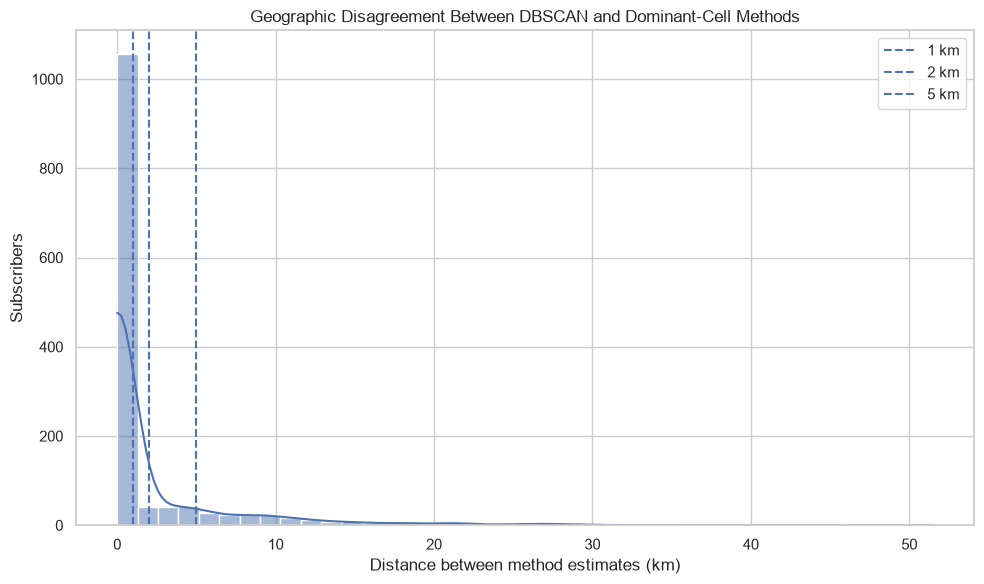

In [304]:
# Visualise disagreement

plt.figure(figsize=(10, 6))

sns.histplot(
    method_comparison["method_distance_km"].dropna(),
    bins=40,
    kde=True
)

plt.axvline(1, linestyle="--", label="1 km")

plt.axvline(2, linestyle="--", label="2 km")

plt.axvline(5, linestyle="--", label="5 km")

plt.title("Geographic Disagreement Between DBSCAN and Dominant-Cell Methods")

plt.xlabel("Distance between method estimates (km)")

plt.ylabel("Subscribers")

plt.legend()

plt.tight_layout()

plt.show()

In [305]:
# Inspect cases with substantial method disagreement

method_disagreement_cases = method_comparison[
    method_comparison["method_distance_km"] > 2
].sort_values(
    "method_distance_km",
    ascending=False
)


print(
    "Subscribers with method disagreement above 2 km:",
    len(method_disagreement_cases)
)


display(
    method_disagreement_cases[
        [
            "inference_observed_nights",
            "method_distance_km",
            "dbscan_cluster_nights",
            "dbscan_estimate_available"
        ]
    ].head(20)
)

Subscribers with method disagreement above 2 km: 284


,inference_observed_nights,method_distance_km,dbscan_cluster_nights,dbscan_estimate_available
55,11,51.508,4,True
658,6,32.916,2,True
516,12,30.145,9,True
100,6,29.293,2,True
706,5,28.209,1,True
721,5,28.040,2,True
1158,7,27.518,3,True
600,6,27.270,2,True
1222,10,26.640,4,True
259,6,26.419,3,True


### Interpretation and Summary

The analysis identifies **284 subscribers with more than 2 km of disagreement** between the dominant nighttime cell method and DBSCAN clustering.

**Key observations:**

- **284 subscribers** have residential location estimates differing by more than 2 km.
- The largest disagreement is approximately **51.5 km**, indicating substantial differences for some subscribers.
- Several cases show disagreements exceeding 20 km.
- Most affected subscribers have relatively limited nighttime observations (typically 5–12 nights).
- DBSCAN sometimes identifies clusters supported by only 1–4 nights, suggesting that its estimated location may be based on limited recurring activity.

**Key takeaway:**

Substantial disagreement between the two methods suggests that some subscribers have multiple nighttime activity locations or insufficiently consistent residential patterns. Limited observations and weak spatial clustering may contribute to these differences.

#### 10.1 Experiment 5 — Confidence assessment and synthetic-reference calibration
This section evaluates whether stronger evidence corresponds to more reliable inferred locations.

A transparent confidence score will be constructed from:
- Dominant-location consistency.
- Number of observed nights.
- Number of separate weeks in which the dominant cell was observed.
These are evidence indicators, not learned model probabilities.

If the synthetic `location_target` field is available, use its home-labelled records only to create an evaluation reference and then compare inferred coordinates against that reference and assess how well the confidence score separates more reliable from less reliable estimates.

In [306]:
# Calculate evidence features
# DOMINANT LOCATION ACTIVE WEEKS

dominant_week_events = (
    inference_events[
        [
            "msisdn",
            "cell_id",
            "night_id"
        ]
    ]
    .drop_duplicates()
    .copy()
)

dominant_week_events["week_id"] = (
    dominant_week_events["night_id"]
    .dt.to_period("W")
    .astype(str)
)


dominant_week_counts = (
    dominant_week_events.groupby(
        [
            "msisdn",
            "cell_id"
        ],
        observed=True
    )
    .agg(
        active_weeks=("week_id", "nunique")
    )
    .reset_index()
)


confidence_data = inference_locations.merge(
    dominant_week_counts,
    left_on=[
        "msisdn",
        "inference_dominant_cell"
    ],
    right_on=[
        "msisdn",
        "cell_id"
    ],
    how="left",
    validate="one_to_one"
)


confidence_data = confidence_data.drop(
    columns=["cell_id"],
    errors="ignore"
)


confidence_data["active_weeks"] = (
    confidence_data["active_weeks"].fillna(0)
)


display(
    confidence_data[
        [
            "msisdn",
            "inference_observed_nights",
            "inference_dominance",
            "active_weeks"
        ]
    ].head(10)
)

,msisdn,inference_observed_nights,inference_dominance,active_weeks
0,subscribers_00002,6,0.500,2
1,subscribers_00003,14,0.786,2
2,subscribers_00005,5,0.200,1
3,subscribers_00007,13,1.000,3
4,subscribers_00008,8,0.750,3
5,subscribers_00010,8,0.875,2
6,subscribers_00012,14,0.929,3
7,subscribers_00014,7,0.143,1
8,subscribers_00016,9,0.333,2
9,subscribers_00017,8,0.875,2


### Interpretation and Summary

The analysis calculates how consistently subscribers return to their inferred dominant nighttime location across different weeks.

**Key findings (1,423 subscribers):**

- **Average observed nights:** 9.3 nights per subscriber.
- **Average dominance ratio:** 63.4%, indicating that, on average, approximately 63% of observed nighttime activity occurs at the dominant cell.
- **Median dominance:** 80%, suggesting relatively concentrated nighttime activity for at least half of subscribers.
- **Active weeks:** 
  - 442 subscribers (31.1%) appeared at their dominant location in 1 week.
  - 361 subscribers (25.4%) appeared in 2 weeks.
  - 620 subscribers (43.6%) appeared in 3 weeks.

**Key takeaway:**

A substantial proportion of subscribers (43.6%) demonstrate recurring nighttime presence at their dominant location across all three observed weeks. However, 31.1% appear in only one week, making their residential estimates less temporally reliable.

In [307]:
# Export Report
confidence_data.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_data.csv",
    index=False
)

#### 10.2 Create an evidence-based confidence score

In [308]:
# EVIDENCE-BASED CONFIDENCE SCORE
confidence_data["night_evidence_score"] = (
    confidence_data["inference_observed_nights"]
    .clip(upper=10) / 10
)

confidence_data["week_evidence_score"] = (
    confidence_data["active_weeks"]
    .clip(upper=2) / 2
)


confidence_data["confidence_score"] = (
    0.50 * confidence_data["inference_dominance"]
    +
    0.30 * confidence_data["night_evidence_score"]
    +
    0.20 * confidence_data["week_evidence_score"]
)


confidence_data["confidence_category"] = pd.cut(
    confidence_data["confidence_score"],
    bins=[
        0,
        0.40,
        0.60,
        0.80,
        1.00
    ],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Very High"
    ],
    include_lowest=True
)


display(
    confidence_data[
        [
            "msisdn",
            "inference_observed_nights",
            "inference_dominance",
            "active_weeks",
            "confidence_score",
            "confidence_category"
        ]
    ].head(20)
)

,msisdn,inference_observed_nights,inference_dominance,active_weeks,confidence_score,confidence_category
0,subscribers_00002,6,0.500,2,0.630,High
1,subscribers_00003,14,0.786,2,0.893,Very High
2,subscribers_00005,5,0.200,1,0.350,Low
3,subscribers_00007,13,1.000,3,1.000,Very High
4,subscribers_00008,8,0.750,3,0.815,Very High
5,subscribers_00010,8,0.875,2,0.877,Very High
6,subscribers_00012,14,0.929,3,0.964,Very High
7,subscribers_00014,7,0.143,1,0.381,Low
8,subscribers_00016,9,0.333,2,0.637,High
9,subscribers_00017,8,0.875,2,0.877,Very High


### Interpretation and Summary

The confidence score combines three indicators to assess the reliability of inferred nighttime residential locations:

- **Nighttime dominance (50%):** How consistently a subscriber appears at their dominant cell.
- **Observed nights (30%):** The number of nights available for inference.
- **Active weeks (20%):** How consistently the dominant location appears across different weeks.

**Key findings (1,423 subscribers):**

| Confidence category | Subscribers | Percentage |
|---|---:|---:|
| Very High | 772 | 54.3% |
| High | 163 | 11.5% |
| Moderate | 151 | 10.6% |
| Low | 337 | 23.7% |

**Key observations:**

- Approximately **65.8%** of subscribers have High or Very High residential-location confidence.
- More than half (54.3%) have Very High confidence, indicating strong nighttime dominance and recurring activity across multiple weeks.
- 23.7% have Low confidence, suggesting insufficiently concentrated or recurring nighttime activity.
- The overall mean confidence score is **0.73**, while the median is **0.85**.

**Conclusion:**

The evidence-based scoring framework provides a practical way to distinguish reliable residential estimates from uncertain ones. Very High and High confidence estimates are suitable for further geographic analysis, while Moderate and Low confidence estimates should be treated cautiously.

*Note: These scores represent analytical confidence based on the selected weighting scheme, not statistically calibrated probabilities that a subscriber lives at a particular location.*

In [309]:
# Export Report
confidence_data.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_data_and_category.csv",
    index=False
)

#### 10.3 Build the synthetic reference dataset

In [310]:
# SYNTHETIC REFERENCE DATA
if "location_target" in df.columns:

    reference_events = df[
        df["location_target"]
        .astype("string")
        .str.lower()
        .eq("home")
    ].copy()

    synthetic_reference = (
        reference_events.groupby("msisdn")
        .agg(
            reference_latitude=("latitude", "median"),
            reference_longitude=("longitude", "median"),
            reference_observations=("datetime", "size")
        )
        .reset_index()
    )

    print(
        "Subscribers with synthetic home reference:",
        synthetic_reference["msisdn"].nunique()
    )

else:

    synthetic_reference = pd.DataFrame(
        columns=[
            "msisdn",
            "reference_latitude",
            "reference_longitude",
            "reference_observations"
        ]
    )

    print(
        "No location_target field available. "
        "Synthetic reference calibration cannot be performed."
    )

Subscribers with synthetic home reference: 2792


#### 10.4 Compare inference against synthetic reference

In [311]:
# SYNTHETIC REFERENCE EVALUATION
confidence_evaluation = confidence_data.merge(
    synthetic_reference,
    on="msisdn",
    how="inner",
    validate="one_to_one"
)


if not confidence_evaluation.empty:

    confidence_evaluation["reference_error_km"] = (
        haversine_km(
            confidence_evaluation["inference_latitude"],
            confidence_evaluation["inference_longitude"],
            confidence_evaluation["reference_latitude"],
            confidence_evaluation["reference_longitude"]
        )
    )

    # Define a reference-based success outcome.
    # This is an evaluation threshold, not a model feature.
    REFERENCE_SUCCESS_DISTANCE_KM = 1.0

    confidence_evaluation["reference_success"] = (
        confidence_evaluation["reference_error_km"]
        <= REFERENCE_SUCCESS_DISTANCE_KM
    ).astype(int)


    print(
        "Subscribers evaluated against synthetic reference:",
        len(confidence_evaluation)
    )

    display(
        confidence_evaluation[
            [
                "confidence_score",
                "confidence_category",
                "reference_error_km",
                "reference_success"
            ]
        ].head(20)
    )

else:

    print(
        "No overlapping subscribers between inference estimates "
        "and synthetic reference records."
    )

Subscribers evaluated against synthetic reference: 1422


,confidence_score,confidence_category,reference_error_km,reference_success
0,0.630,High,11.429,0
1,0.893,Very High,0.000,1
2,0.350,Low,7.304,0
3,1.000,Very High,1.879,0
4,0.815,Very High,0.000,1
5,0.877,Very High,0.000,1
6,0.964,Very High,0.000,1
7,0.381,Low,7.061,0
8,0.637,High,0.000,1
9,0.877,Very High,0.000,1


### Interpretation and Summary

The analysis evaluates how well the inferred residential locations match the synthetic reference locations, using a **1 km distance threshold** as the success criterion.

**Key findings (1,422 subscribers evaluated):**

- **67.4%** of inferred locations fall within 1 km of their synthetic reference.
- **72.2%** fall within 2 km.
- **83.8%** fall within 5 km.
- Median geographic error is **0 km**, indicating that at least half of the inferred locations exactly match the reference coordinates.

**Performance by confidence category:**

| Confidence category | Subscribers | Within 1 km |
|---|---:|---:|
| Very High | 772 | 94.8% |
| High | 162 | 84.6% |
| Moderate | 151 | 29.1% |
| Low | 337 | 13.6% |

**Key observations:**

- Very High confidence estimates demonstrate the strongest agreement with the synthetic reference.
- High confidence estimates also perform well, with 84.6% achieving the 1 km threshold.
- Moderate and Low confidence estimates show substantially weaker geographic accuracy.
- The results suggest that the evidence-based confidence score effectively distinguishes more reliable residential estimates from less reliable ones.

**Conclusion:**

The confidence-scoring framework demonstrates promising discriminatory ability. Subscribers classified as Very High or High confidence have substantially better geographic agreement with the synthetic reference.

*Important limitation:* This evaluation measures agreement with synthetic reference locations, not independently verified actual residences. The results should therefore be interpreted as validation against a constructed reference rather than definitive residential-location accuracy.

In [312]:
# Export Report
confidence_evaluation.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_evaluation.csv",
    index=False
)

#### 10.5 Evaluate confidence by category

In [313]:
if not confidence_evaluation.empty:

    confidence_calibration_summary = (
        confidence_evaluation.groupby(
            "confidence_category",
            observed=True
        )
        .agg(
            subscribers=("msisdn", "nunique"),
            mean_confidence=("confidence_score", "mean"),
            mean_reference_error_km=("reference_error_km", "mean"),
            median_reference_error_km=("reference_error_km", "median"),
            reference_success_rate=("reference_success", "mean")
        )
        .reset_index()
    )

    confidence_calibration_summary["reference_success_rate_pct"] = (
        confidence_calibration_summary["reference_success_rate"] * 100
    )

    display(confidence_calibration_summary)

else:

    confidence_calibration_summary = pd.DataFrame()

,confidence_category,subscribers,mean_confidence,mean_reference_error_km,median_reference_error_km,reference_success_rate,reference_success_rate_pct
0,Low,337,0.361,7.101,4.877,0.136,13.650
1,Moderate,151,0.479,4.997,2.338,0.291,29.139
2,High,162,0.717,0.553,0.000,0.846,84.568
3,Very High,772,0.943,0.208,0.000,0.948,94.819


### Interpretation and Summary

The results demonstrate a strong relationship between the confidence score and the geographic accuracy of inferred residential locations.

**Key findings:**

| Confidence category | Subscribers | Mean error (km) | Success within 1 km |
|---|---:|---:|---:|
| Low | 337 | 7.10 | 13.7% |
| Moderate | 151 | 5.00 | 29.1% |
| High | 162 | 0.55 | 84.6% |
| Very High | 772 | 0.21 | 94.8% |

**Key observations:**

- **Very High confidence:** 94.8% of subscribers have inferred locations within 1 km of their synthetic reference, with a mean geographic error of just 0.21 km.
- **High confidence:** 84.6% achieve the 1 km accuracy threshold.
- **Moderate confidence:** Accuracy drops considerably, with only 29.1% within 1 km.
- **Low confidence:** Only 13.7% achieve the 1 km threshold, with a mean error of 7.10 km.
- Geographic accuracy improves consistently as confidence increases.

**Conclusion:**

The confidence framework demonstrates strong discriminatory and calibration potential. It successfully separates reliable residential estimates from weaker estimates, with Very High confidence subscribers showing the best geographic agreement.

**Recommendation:** Prioritise Very High and High confidence estimates for downstream geographic analysis. Treat Moderate estimates cautiously and exclude Low confidence estimates from analyses requiring precise residential locations.

*Note: Validation is against synthetic reference locations, not independently verified subscriber residences.*

#### 10.6 Calculate calibration metrics

In [314]:
if (
    not confidence_evaluation.empty
    and confidence_evaluation["reference_success"].nunique() == 2
):

    brier_score = brier_score_loss(
        confidence_evaluation["reference_success"],
        confidence_evaluation["confidence_score"]
    )

    auc_score = roc_auc_score(
        confidence_evaluation["reference_success"],
        confidence_evaluation["confidence_score"]
    )

    print("Brier score:", round(brier_score, 4))

    print("ROC AUC:", round(auc_score, 4))

else:

    brier_score = np.nan
    auc_score = np.nan

    print(
        "Brier score and ROC AUC cannot be calculated "
        "because the evaluation outcome has insufficient class variation."
    )

Brier score: 0.108
ROC AUC: 0.9051


### Interpretation and Summary

The evaluation assesses how effectively the evidence-based confidence score distinguishes accurate residential-location estimates from inaccurate ones.

**Key findings:**

- **Brier Score: 0.108** – Indicates good predictive performance, with relatively low error between the confidence scores and actual evaluation outcomes. Lower values indicate better performance.
- **ROC AUC: 0.9051** – Indicates excellent discriminatory ability. The confidence score can effectively distinguish subscribers whose inferred locations fall within 1 km of the synthetic reference from those whose locations do not.

**Key observations:**

- The ROC AUC of approximately 0.91 suggests that the confidence framework ranks successful location estimates substantially higher than unsuccessful ones.
- The Brier score of 0.108 suggests promising agreement between confidence scores and reference-based outcomes.
- Together, these metrics provide evidence that the confidence framework is useful for identifying reliable residential-location estimates.

**Conclusion:**

The confidence-scoring framework demonstrates strong discriminatory performance and promising predictive quality. The ROC AUC of 0.9051 is particularly encouraging, suggesting that the framework effectively separates reliable from less reliable residential estimates.

*Note: These results are based on synthetic reference locations. The Brier score alone does not establish calibration, and further validation against independently verified residential locations is recommended.*

#### 10.7 Plot the reliability curve

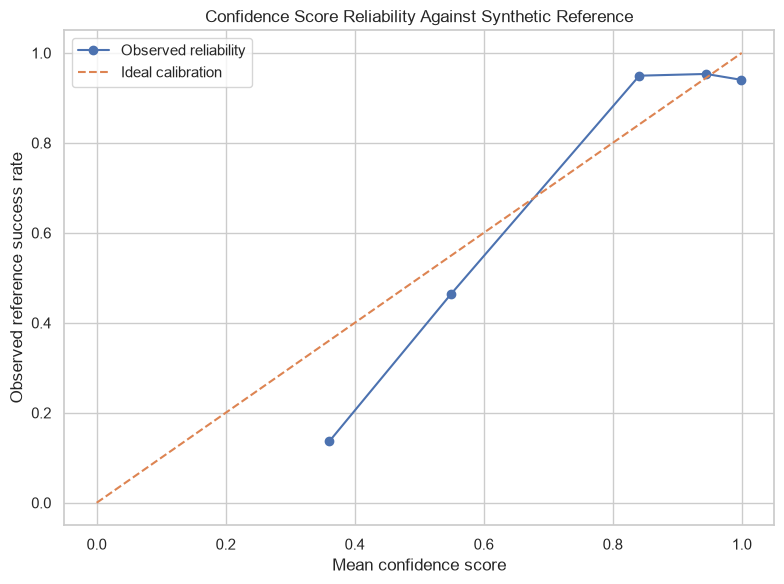

In [315]:
if (
    not confidence_evaluation.empty
    and confidence_evaluation["reference_success"].nunique() == 2
):

    observed_success, predicted_confidence = calibration_curve(
        confidence_evaluation["reference_success"],
        confidence_evaluation["confidence_score"],
        n_bins=5,
        strategy="quantile"
    )

    plt.figure(figsize=(8, 6))

    plt.plot(
        predicted_confidence,
        observed_success,
        marker="o",
        label="Observed reliability"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Ideal calibration"
    )

    plt.title("Confidence Score Reliability Against Synthetic Reference")

    plt.xlabel("Mean confidence score")

    plt.ylabel("Observed reference success rate")

    plt.legend()

    plt.tight_layout()

    plt.show()

else:

    print("Reliability curve unavailable.")

### Interpretation and Summary

The reliability diagram evaluates how closely the confidence scores correspond to the observed success rates against the synthetic reference locations.

**Key observations:**

- **Low confidence scores (0.35–0.55):** Observed success rates are relatively low, approximately 14%–46%. The model slightly overestimates reliability in this range.
- **High confidence scores (0.84–1.00):** Observed success rates are approximately 94%–95%, indicating strong reliability.
- **Very high confidence:** Scores around 0.85–0.95 align closely with the ideal calibration line.
- **Overall:** The confidence framework distinguishes reliable estimates effectively, although calibration is weaker at lower confidence levels.

**Conclusion:**

The reliability curve supports the usefulness of the confidence-scoring framework. High-confidence estimates demonstrate strong agreement with synthetic reference outcomes, while lower-confidence estimates tend to be overconfident.

Further calibration, particularly for Low and Moderate confidence scores, could improve reliability.

*Note: Evaluation is based on synthetic reference locations, not independently verified residential addresses.*

#### 11. Experiment 6 — No-ground-truth diagnostics

Not every MNO dataset will have reliable reference locations. This section provides diagnostics that can still be used when ground truth is unavailable.

Assess:
- Whether estimates remain stable between observation periods.
- Whether independent inference methods produce similar locations.
- Whether estimates have sufficient observations.
- Whether confidence scores increase with stronger evidence.
- Whether the methodology produces an appropriate number of abstentions.

In [316]:
# NO-GROUND-TRUTH DIAGNOSTICS
no_ground_truth_diagnostics = pd.DataFrame({
    "diagnostic": [
        "Temporal holdout subscribers",
        "Median temporal location difference (km)",
        "Temporal agreement within 1 km (%)",
        "Temporal agreement within 2 km (%)",
        "Temporal agreement within 5 km (%)",
        "Subscribers with DBSCAN estimate",
        "Median DBSCAN-method disagreement (km)",
        "Subscribers with confidence estimates",
        "Subscribers with low confidence",
        "Subscribers with high or very high confidence"
    ],
    "value": [
        len(temporal_holdout),
        temporal_holdout["holdout_geographic_error_km"].median(),
        temporal_holdout["within_1km"].mean() * 100,
        temporal_holdout["within_2km"].mean() * 100,
        temporal_holdout["within_5km"].mean() * 100,
        dbscan_results["dbscan_estimate_available"].sum(),
        method_comparison["method_distance_km"].median(),
        len(confidence_data),
        confidence_data["confidence_category"].eq("Low").sum(),
        confidence_data["confidence_category"].isin(
            ["High", "Very High"]
        ).sum()
    ]
})


display(no_ground_truth_diagnostics)

,diagnostic,value
0,Temporal holdout subscribers,"1,114.000"
1,Median temporal location difference (km),0.000
2,Temporal agreement within 1 km (%),78.636
3,Temporal agreement within 2 km (%),80.790
4,Temporal agreement within 5 km (%),88.241
5,Subscribers with DBSCAN estimate,"1,364.000"
6,Median DBSCAN-method disagreement (km),0.000
7,Subscribers with confidence estimates,"1,423.000"
8,Subscribers with low confidence,337.000
9,Subscribers with high or very high confidence,935.000


### Interpretation and Summary

The analysis evaluates the reliability of inferred residential locations using temporal consistency, agreement between inference methods, and confidence scores, without relying on independently verified ground-truth locations.

**Key findings:**

- **Temporal consistency:** 1,114 subscribers were evaluated. Approximately 78.6% had location estimates within 1 km, 80.8% within 2 km, and 88.2% within 5 km across the two periods.
- **Method agreement:** DBSCAN produced estimates for 1,364 subscribers. The median disagreement between DBSCAN and the primary inference method was 0 km, indicating strong agreement for at least half of evaluated subscribers.
- **Confidence coverage:** Confidence scores were generated for 1,423 subscribers.
- **High-confidence estimates:** 935 subscribers (65.7%) were classified as High or Very High confidence.
- **Low-confidence estimates:** 337 subscribers (23.7%) were classified as Low confidence and should be treated cautiously.

**Key observations:**

- Temporal consistency provides evidence that inferred residential locations are repeatable across observation periods.
- Agreement between the primary inference method and DBSCAN provides additional methodological support.
- The confidence framework identifies a substantial group of subscribers with relatively reliable residential estimates.
- However, temporal consistency and agreement between methods do not independently establish actual residential-location accuracy.

**Conclusion:**

The combined diagnostics provide encouraging evidence of methodological robustness. The residential inference framework demonstrates temporal stability, reasonable agreement between independent clustering approaches, and the ability to distinguish stronger estimates from weaker ones through confidence scoring.

*Important limitation: These diagnostics assess internal consistency and methodological agreement, not verified residential-location accuracy. Independent ground-truth validation remains necessary before making definitive claims about actual subscriber residences.*

#### 11.1 Compare confidence with temporal consistency

In [317]:
confidence_temporal = confidence_data.merge(
    temporal_holdout[
        [
            "msisdn",
            "holdout_geographic_error_km",
            "within_1km",
            "within_2km",
            "within_5km"
        ]
    ],
    on="msisdn",
    how="inner",
    validate="one_to_one"
)


confidence_temporal_summary = (
    confidence_temporal.groupby(
        "confidence_category",
        observed=True
    )
    .agg(
        subscribers=("msisdn", "nunique"),
        mean_confidence=("confidence_score", "mean"),
        median_temporal_difference_km=(
            "holdout_geographic_error_km",
            "median"
        ),
        within_2km_rate=("within_2km", "mean")
    )
    .reset_index()
)


confidence_temporal_summary["within_2km_pct"] = (
    confidence_temporal_summary["within_2km_rate"] * 100
)


display(confidence_temporal_summary)

,confidence_category,subscribers,mean_confidence,median_temporal_difference_km,within_2km_rate,within_2km_pct
0,Low,163,0.362,4.874,0.202,20.245
1,Moderate,99,0.483,4.494,0.273,27.273
2,High,102,0.717,0.000,0.882,88.235
3,Very High,750,0.945,0.000,1.000,100.000


### Interpretation and Summary

The analysis evaluates whether the confidence score is associated with the temporal consistency of inferred residential locations across the inference and holdout periods.

**Key findings:**

| Confidence category | Subscribers | Median location difference (km) | Within 2 km |
|---|---:|---:|---:|
| Low | 163 | 4.87 | 20.2% |
| Moderate | 99 | 4.49 | 27.3% |
| High | 102 | 0.00 | 88.2% |
| Very High | 750 | 0.00 | 100.0% |

**Key observations:**

- **Very High confidence:** All 750 subscribers (100%) have consistent inferred locations within 2 km across both periods.
- **High confidence:** 88.2% demonstrate temporal consistency within 2 km.
- **Moderate confidence:** Only 27.3% achieve the 2 km threshold, indicating weaker temporal stability.
- **Low confidence:** Just 20.2% achieve the threshold, suggesting substantial instability in inferred residential locations.
- The median location difference is zero for both High and Very High confidence groups, indicating that at least half of subscribers in these categories have matching inferred locations.

**Conclusion:**

The results provide strong evidence that the confidence-scoring framework captures temporal consistency, not just agreement with the synthetic reference. High and Very High confidence estimates demonstrate substantially greater stability across observation periods.

**Recommendation:** Prioritise High and Very High confidence subscribers for downstream residential and geographic analysis. Treat Moderate and Low confidence estimates cautiously.

*Note: Temporal consistency indicates repeatability of inferred locations, not necessarily confirmation of actual residential addresses.*

#### 12. Experiment 7 — Grid alignment sensitivity

In [318]:
# RECREATE MOVEMENT ANALYSIS OF NOTEBOOK 04 FOR NOTEBOOK 05
# Infer baseline nighttime locations

baseline_locations = infer_dominant_locations(
    inference_events,
    min_nights=BASELINE_MIN_NIGHTS
)

baseline_locations = baseline_locations.rename(
    columns={
        "dominant_cell": "baseline_dominant_cell",
        "dominant_latitude": "baseline_latitude",
        "dominant_longitude": "baseline_longitude",
        "observed_nights": "baseline_observed_nights",
        "dominance_share": "baseline_dominance"
    }
)


# Infer follow-up nighttime locations
followup_locations = infer_dominant_locations(
    holdout_events,
    min_nights=FOLLOWUP_MIN_NIGHTS
)

followup_locations = followup_locations.rename(
    columns={
        "dominant_cell": "followup_dominant_cell",
        "dominant_latitude": "followup_latitude",
        "dominant_longitude": "followup_longitude",
        "observed_nights": "followup_observed_nights",
        "dominance_share": "followup_dominance"
    }
)


# Combine both periods
movement_analysis = baseline_locations.merge(
    followup_locations,
    on="msisdn",
    how="inner",
    validate="one_to_one"
)


# Calculate geographic movement
movement_analysis["baseline_to_followup_distance_km"] = (
    haversine_km(
        movement_analysis["baseline_latitude"],
        movement_analysis["baseline_longitude"],
        movement_analysis["followup_latitude"],
        movement_analysis["followup_longitude"]
    )
)


# Identify meaningful geographic changes
movement_analysis["meaningful_geographic_shift"] = (
    movement_analysis["baseline_to_followup_distance_km"]
    >= MOVEMENT_DISTANCE_KM
)


print(
    "Subscribers in movement analysis:",
    movement_analysis["msisdn"].nunique()
)

print(
    "Subscribers with meaningful geographic shifts:",
    movement_analysis["meaningful_geographic_shift"].sum()
)

display(movement_analysis.head())

Subscribers in movement analysis: 1114
Subscribers with meaningful geographic shifts: 131


,msisdn,baseline_dominant_cell,dominant_nights_x,baseline_latitude,baseline_longitude,baseline_observed_nights,baseline_dominance,followup_dominant_cell,dominant_nights_y,followup_latitude,followup_longitude,followup_observed_nights,followup_dominance,baseline_to_followup_distance_km,meaningful_geographic_shift
0,subscribers_00002,28284,3,-1.220,36.887,6,0.500,22951,7,-1.319,36.862,10,0.700,11.429,True
1,subscribers_00003,18804,11,-1.274,36.837,14,0.786,18804,11,-1.274,36.837,12,0.917,0.000,False
2,subscribers_00005,13984,1,-1.289,36.816,5,0.200,15009,1,-1.323,36.820,7,0.143,3.807,False
3,subscribers_00007,28155,13,-1.191,36.887,13,1.000,28155,11,-1.191,36.887,12,0.917,0.000,False
4,subscribers_00008,2047,6,-1.248,36.664,8,0.750,2047,6,-1.248,36.664,7,0.857,0.000,False


### Interpretation and Summary

The analysis compares subscribers' dominant nighttime locations between the baseline and follow-up periods to identify potential geographic movement.

**Key findings (1,114 subscribers):**

- **983 subscribers (88.2%)** showed no meaningful geographic shift.
- **131 subscribers (11.8%)** experienced a meaningful geographic shift based on the configured movement threshold of 5 km.
- Median baseline-to-follow-up distance was **0 km**, indicating that at least half of subscribers retained the same dominant nighttime location.
- The mean geographic distance was approximately **1.64 km**.
- The maximum observed location difference was approximately **52.07 km**.

**Key observations:**

- Most subscribers maintained consistent dominant nighttime locations across both periods.
- A smaller proportion (11.8%) exhibited geographic changes exceeding the 5 km threshold.
- The results suggest that nighttime residential patterns were relatively stable for most subscribers.
- The 131 subscribers with meaningful shifts warrant further investigation to determine whether these changes represent relocation, temporary movement or changes in nighttime activity patterns.

**Conclusion:**

The analysis identifies 131 potential geographic movement cases among 1,114 subscribers, while the remaining 88.2% maintained relatively stable nighttime locations.

These movements should be treated as potential mobility signals rather than confirmed residential displacement, since changes in dominant nighttime cell locations do not independently establish a change of residence.

In [319]:
# Export Report
movement_analysis.to_csv(
    NOTEBOOK05_OUTPUT / "movement_analysis.csv",
    index=False
)

In [320]:
# GRID ALIGNMENT SENSITIVITY

GRID_SIZE = 0.05

grid_offsets = [
    (0.00, 0.00),
    (0.025, 0.025),
    (0.025, 0.00),
    (0.00, 0.025)
]

alignment_results = []

for lat_offset, lon_offset in grid_offsets:

    temp = movement_analysis[
        movement_analysis["meaningful_geographic_shift"].eq(True)
        &
        movement_analysis["followup_latitude"].notna()
        &
        movement_analysis["followup_longitude"].notna()
    ].copy()

    temp["lat_zone"] = (
        np.floor(
            (temp["followup_latitude"] - lat_offset)
            / GRID_SIZE
        ) * GRID_SIZE + lat_offset
    )

    temp["lon_zone"] = (
        np.floor(
            (temp["followup_longitude"] - lon_offset)
            / GRID_SIZE
        ) * GRID_SIZE + lon_offset
    )

    zones = (
        temp.groupby(
            ["lat_zone", "lon_zone"],
            observed=True
        )
        .agg(
            subscriber_count=("msisdn", "nunique")
        )
        .reset_index()
    )

    alignment_results.append({
        "latitude_offset": lat_offset,
        "longitude_offset": lon_offset,
        "total_zones": len(zones),
        "publishable_zones": (
            zones["subscriber_count"] >= MIN_FLOW_SUBSCRIBERS
        ).sum(),
        "suppressed_zones": (
            zones["subscriber_count"] < MIN_FLOW_SUBSCRIBERS
        ).sum()
    })


grid_alignment_sensitivity = pd.DataFrame(
    alignment_results
)

display(grid_alignment_sensitivity)

,latitude_offset,longitude_offset,total_zones,publishable_zones,suppressed_zones
0,0.000,0.000,27,9,18
1,0.025,0.025,29,9,20
2,0.025,0.000,29,9,20
3,0.000,0.025,28,9,19


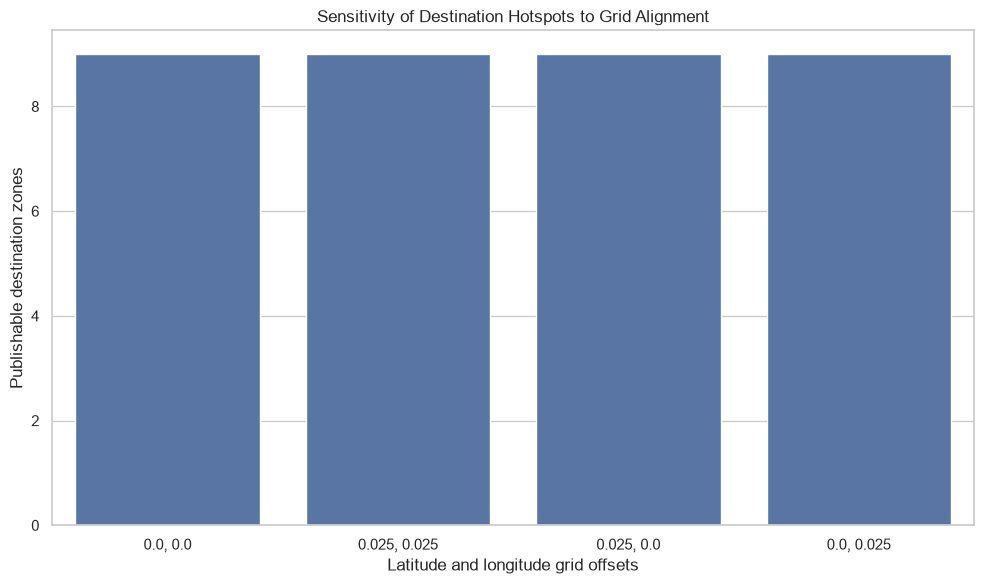

In [321]:
# Compare the geographic aggregation configurations

plt.figure(figsize=(10, 6))

sns.barplot(
    data=grid_alignment_sensitivity,
    x=(
        grid_alignment_sensitivity["latitude_offset"].astype(str)
        + ", "
        + grid_alignment_sensitivity["longitude_offset"].astype(str)
    ),
    y="publishable_zones"
)

plt.title("Sensitivity of Destination Hotspots to Grid Alignment")

plt.xlabel("Latitude and longitude grid offsets")

plt.ylabel("Publishable destination zones")

plt.tight_layout()

plt.show()

### Interpretation and Summary

The analysis examines whether the number of publishable destination hotspots changes when the geographic grid alignment is shifted.

**Key findings:**

- All four grid configurations produced **9 publishable destination zones**.
- The configurations tested different latitude and longitude offsets: (0.0, 0.0), (0.025, 0.025), (0.025, 0.0) and (0.0, 0.025).
- The number of publishable zones remained unchanged across all configurations.

**Key observations:**

- Destination hotspot identification appears robust to the tested grid-alignment changes.
- Shifting the grid boundaries did not materially affect the number of geographic zones meeting the publication threshold.
- This suggests that the identified destination hotspots are not simply artefacts of one particular grid alignment.

**Conclusion:**

The geographic hotspot analysis demonstrates good sensitivity to grid alignment. The consistent identification of 9 publishable zones across all four configurations supports using the original grid alignment for subsequent geographic analysis.

*Note: Consistency in hotspot counts does not necessarily mean that the exact subscribers or geographic boundaries within each zone remained identical across configurations.*

#### 13. Overall robustness assessment

Combine the results from the different experiments into a single summary.

In [322]:
# VALIDATION RESULTS SUMMARY

validation_summary = pd.DataFrame([
    {
        "experiment": "Temporal holdout",
        "metric": "Subscribers evaluated",
        "value": len(temporal_holdout)
    },
    {
        "experiment": "Temporal holdout",
        "metric": "Median geographic difference (km)",
        "value": temporal_holdout[
            "holdout_geographic_error_km"
        ].median()
    },
    {
        "experiment": "Nighttime window sensitivity",
        "metric": "Number of tested windows",
        "value": len(night_window_sensitivity)
    },
    {
        "experiment": "Parameter sensitivity",
        "metric": "Number of configurations tested",
        "value": len(parameter_sensitivity)
    },
    {
        "experiment": "Method disagreement",
        "metric": "Subscribers compared",
        "value": len(method_comparison)
    },
    {
        "experiment": "Method disagreement",
        "metric": "Median disagreement (km)",
        "value": method_comparison[
            "method_distance_km"
        ].median()
    },
    {
        "experiment": "Confidence assessment",
        "metric": "Subscribers with confidence estimates",
        "value": len(confidence_data)
    },
    {
        "experiment": "Synthetic reference",
        "metric": "Subscribers evaluated",
        "value": len(confidence_evaluation)
    },
    {
        "experiment": "Grid alignment",
        "metric": "Configurations tested",
        "value": len(grid_alignment_sensitivity)
    }
])


display(validation_summary)

,experiment,metric,value
0,Temporal holdout,Subscribers evaluated,"1,114.000"
1,Temporal holdout,Median geographic difference (km),0.000
2,Nighttime window sensitivity,Number of tested windows,4.000
3,Parameter sensitivity,Number of configurations tested,64.000
4,Method disagreement,Subscribers compared,"1,423.000"
5,Method disagreement,Median disagreement (km),0.000
6,Confidence assessment,Subscribers with confidence estimates,"1,423.000"
7,Synthetic reference,Subscribers evaluated,"1,422.000"
8,Grid alignment,Configurations tested,4.000


### Interpretation and Summary

The validation summary brings together the key experiments conducted to assess the robustness, consistency and reliability of the residential-location inference framework.

**Key findings:**

- **Temporal holdout:** 1,114 subscribers were evaluated, with a median geographic difference of 0 km between inference and holdout estimates, indicating strong temporal consistency.
- **Nighttime window sensitivity:** Four different nighttime observation windows were tested to assess whether residential estimates depend on the selected observation period.
- **Parameter sensitivity:** 64 parameter configurations were evaluated to understand how analytical thresholds affect movement detection.
- **Method disagreement:** 1,423 subscribers were compared across the primary inference method and DBSCAN, with a median disagreement of 0 km.
- **Confidence assessment:** Confidence scores were generated for 1,423 subscribers to distinguish reliable residential estimates from uncertain ones.
- **Synthetic reference validation:** 1,422 subscribers were evaluated against synthetic reference locations to assess geographic accuracy.
- **Grid alignment:** Four geographic grid configurations were tested to determine the sensitivity of destination hotspot identification to grid boundaries.

**Key takeaway:**

The validation experiments provide encouraging evidence that the framework is robust across different observation windows, analytical parameters, inference methods and geographic aggregation configurations.

The combination of temporal holdout testing, independent clustering comparison, synthetic reference evaluation and confidence scoring provides multiple complementary ways to assess inference quality.

**Conclusion:**

The residential-location inference framework demonstrates promising methodological robustness and repeatability. Its confidence-scoring component provides an additional mechanism for identifying reliable estimates and managing uncertainty.

*Important limitation: These experiments establish internal consistency and agreement against synthetic references, not definitive accuracy against independently verified residential addresses.*

In [323]:
# Identify sensitivity in the main parameters
# SUMMARISE PARAMETER SENSITIVITY

parameter_impact = (
    parameter_sensitivity.groupby(
        [
            "minimum_observed_nights",
            "minimum_dominance"
        ]
    )
    .agg(
        minimum_candidates=("movement_candidates", "min"),
        maximum_candidates=("movement_candidates", "max"),
        average_candidates=("movement_candidates", "mean")
    )
    .reset_index()
)


parameter_impact["candidate_range"] = (
    parameter_impact["maximum_candidates"]
    - parameter_impact["minimum_candidates"]
)


display(
    parameter_impact.sort_values(
        "candidate_range",
        ascending=False
    )
)

,minimum_observed_nights,minimum_dominance,minimum_candidates,maximum_candidates,average_candidates,candidate_range
0,3,0.300,3,48,23.500,45
1,3,0.400,0,5,2.250,5
2,3,0.500,0,5,2.250,5
4,5,0.300,0,4,1.750,4
5,5,0.400,0,3,1.250,3
6,5,0.500,0,3,1.250,3
3,3,0.600,0,0,0.000,0
7,5,0.600,0,0,0.000,0
8,7,0.300,0,0,0.000,0
9,7,0.400,0,0,0.000,0


### Interpretation and Summary

The parameter sensitivity analysis shows that **movement candidate identification is highly sensitive to the minimum observed nights, dominance threshold and geographic movement threshold.**

**Key findings:**

- **Minimum 3 observed nights and 0.30 dominance:** Produces the highest number of candidates, averaging 23.5, with a range of 3–48 candidates depending on the movement threshold.
- **Increasing dominance to 0.40 or 0.50:** Dramatically reduces candidate counts, with averages falling to approximately 2.25.
- **Increasing minimum observed nights to 5:** Further reduces the number of candidates, with averages between 1.25 and 1.75.
- **Minimum 7 or 10 observed nights:** Produces zero movement candidates across all tested dominance and distance thresholds.
- **Dominance threshold of 0.60:** Produces zero candidates even with only three observed nights.

**Key takeaway:**

The results suggest that relatively few subscribers demonstrate sufficiently strong and consistent evidence of geographic movement. Relaxing the evidence requirements substantially increases candidate counts, but may introduce less reliable movement signals.

**Conclusion:**

A minimum of 5 observed nights and a dominance threshold of 0.40–0.50 provides a more conservative starting point for identifying potential movement candidates. However, the final thresholds should balance detection sensitivity against confidence in the inferred locations.

Importantly, zero candidates under stricter thresholds does not necessarily mean that no movement occurred; it means no subscriber satisfied all the selected analytical conditions.

#### 14. Export Notebook 05 outputs

In [324]:
# EXPORT VALIDATION OUTPUTS

# 1. Temporal holdout results — subscriber-level.
temporal_holdout.to_csv(
    NOTEBOOK05_OUTPUT / "temporal_holdout_results_private.csv",
    index=False
)


# 2. Temporal holdout metrics.
temporal_holdout_metrics.to_csv(
    NOTEBOOK05_OUTPUT / "temporal_holdout_metrics.csv",
    index=False
)


# 3. Temporal consistency by evidence strength.
temporal_consistency_by_evidence.to_csv(
    NOTEBOOK05_OUTPUT / "temporal_consistency_by_evidence.csv",
    index=False
)


# 4. Nighttime window sensitivity.
night_window_sensitivity.to_csv(
    NOTEBOOK05_OUTPUT / "night_window_sensitivity.csv",
    index=False
)


# 5. Agreement between nighttime windows.
window_agreement.to_csv(
    NOTEBOOK05_OUTPUT / "night_window_agreement.csv",
    index=False
)


# 6. Parameter sensitivity.
parameter_sensitivity.to_csv(
    NOTEBOOK05_OUTPUT / "parameter_sensitivity.csv",
    index=False
)


# 7. Method comparison — subscriber-level.
method_comparison.to_csv(
    NOTEBOOK05_OUTPUT / "method_comparison_private.csv",
    index=False
)


# 8. Method disagreement summary.
method_comparison_summary.to_csv(
    NOTEBOOK05_OUTPUT / "method_disagreement_summary.csv",
    index=False
)


# 9. Confidence evaluation — subscriber-level.
confidence_evaluation.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_evaluation_private.csv",
    index=False
)


# 10. Confidence calibration summary.
confidence_calibration_summary.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_calibration_summary.csv",
    index=False
)


# 11. No-ground-truth diagnostics.
no_ground_truth_diagnostics.to_csv(
    NOTEBOOK05_OUTPUT / "no_ground_truth_diagnostics.csv",
    index=False
)


# 12. Confidence versus temporal stability.
confidence_temporal_summary.to_csv(
    NOTEBOOK05_OUTPUT / "confidence_temporal_stability.csv",
    index=False
)


# 13. Grid alignment sensitivity.
grid_alignment_sensitivity.to_csv(
    NOTEBOOK05_OUTPUT / "grid_alignment_sensitivity.csv",
    index=False
)


# 14. Overall validation summary.
validation_summary.to_csv(
    NOTEBOOK05_OUTPUT / "validation_summary.csv",
    index=False
)


# 15. Parameter impact.
parameter_impact.to_csv(
    NOTEBOOK05_OUTPUT / "parameter_impact_summary.csv",
    index=False
)


print("Notebook 05 exports completed.")

print("Output directory:", NOTEBOOK05_OUTPUT)

for file in sorted(NOTEBOOK05_OUTPUT.glob("*.csv")):
    print(file.name, "-", f"{file.stat().st_size:,} bytes")

Notebook 05 exports completed.
Output directory: /Users/Apple/Documents/mno_mobility_intelligence_residence_and_population_displacement_inference/data/processed/notebook_05
confidence_calibration_summary.csv - 536 bytes
confidence_data.csv - 82,856 bytes
confidence_data_and_category.csv - 124,463 bytes
confidence_evaluation.csv - 169,257 bytes
confidence_evaluation_private.csv - 169,257 bytes
confidence_temporal_stability.csv - 396 bytes
grid_alignment_sensitivity.csv - 152 bytes
method_comparison_private.csv - 119,365 bytes
method_disagreement_summary.csv - 277 bytes
movement_analysis.csv - 120,644 bytes
night_window_agreement.csv - 286 bytes
night_window_sensitivity.csv - 371 bytes
no_ground_truth_diagnostics.csv - 475 bytes
parameter_impact_summary.csv - 383 bytes
parameter_sensitivity.csv - 1,657 bytes
temporal_consistency_by_evidence.csv - 263 bytes
temporal_holdout_comparison.csv - 131,384 bytes
temporal_holdout_metrics.csv - 282 bytes
temporal_holdout_results_private.csv - 145,5

#### 15. Final quality checks

This section checks that the experiments have produced valid results and that subscriber identifiers are not included in aggregate summaries.

In [325]:
# NOTEBOOK 05 QUALITY CHECKS
# One row per subscriber in the holdout dataset.

assert temporal_holdout["msisdn"].is_unique

# One row per subscriber in the method comparison.
assert method_comparison["msisdn"].is_unique

# Confidence scores must be between 0 and 1.
assert confidence_data["confidence_score"].between(
    0,
    1
).all()

# Geographic distances cannot be negative.
assert (
    temporal_holdout["holdout_geographic_error_km"].dropna()
    >= 0
).all()

assert (
    method_comparison["method_distance_km"].dropna()
    >= 0
).all()

# Check that sensitivity experiments ran.
assert len(night_window_sensitivity) > 0

assert len(parameter_sensitivity) > 0

assert len(grid_alignment_sensitivity) > 0

# Aggregate summaries must not contain subscriber identifiers.
aggregate_outputs = [
    temporal_holdout_metrics,
    temporal_consistency_by_evidence,
    night_window_sensitivity,
    window_agreement,
    parameter_sensitivity,
    method_comparison_summary,
    confidence_calibration_summary,
    no_ground_truth_diagnostics,
    confidence_temporal_summary,
    grid_alignment_sensitivity,
    validation_summary,
    parameter_impact
]

for output in aggregate_outputs:

    assert "msisdn" not in output.columns


print("All Notebook 05 quality checks passed.")

All Notebook 05 quality checks passed.


#### 16. Key findings and interpretation

#### 14. Key Findings and Interpretation

#### 14.1 Overview

This notebook evaluates the reliability, robustness and methodological stability of the residential-location inference and population mobility framework developed in the preceding notebooks.

Seven validation experiments were conducted to determine whether inferred residential locations remain consistent across observation periods, how sensitive movement estimates are to analytical assumptions, and how reliably the methodology distinguishes strong residential signals from uncertain ones.

The experiments cover:

1. Temporal holdout validation.
2. Nighttime window sensitivity.
3. Observation and movement threshold sensitivity.
4. Comparison of DBSCAN and dominant-cell aggregation.
5. Confidence scoring and synthetic-reference evaluation.
6. No-ground-truth reliability diagnostics.
7. Geographic grid-alignment sensitivity.

The objective is not simply to identify potential residential locations but also to establish when the available evidence is insufficient to support a reliable inference.

---

#### 14.2 Key Findings and Interpretation

#### 1. Temporal holdout validation demonstrates strong residential-location consistency

The temporal holdout experiment compared inferred nighttime residential locations from February 1–14, 2026, against locations observed between February 15–28, 2026.

A total of 1,114 subscribers were evaluated.

**Key findings:**

- 78.64% of subscribers had geographic differences within 1 km.
- 80.79% had geographic differences within 2 km.
- 88.24% had geographic differences within 5 km.
- Median geographic difference was 0 km.
- Mean geographic difference was 1.64 km.
- 95th percentile geographic difference was 9.82 km.
- Maximum geographic difference was 52.07 km.

**Interpretation:**

The results demonstrate strong temporal consistency in inferred residential locations. Approximately 88% of evaluated subscribers maintained locations within 5 km across the two observation periods.

The median geographic difference of zero indicates that at least half of the evaluated subscribers retained matching inferred coordinates across both periods.

However, a small proportion of subscribers exhibited substantial geographic differences, including 16 subscribers with differences exceeding 20 km.

The amount of observation evidence also had a significant relationship with temporal consistency:

| Observed nights | Subscribers | Median error (km) | Within 2 km |
|---|---:|---:|---:|
| 7–9 nights | 194 | 2.99 | 42.27% |
| 10–12 nights | 260 | 0.00 | 68.85% |
| 13–14 nights | 660 | 0.00 | 96.82% |

Subscribers with 13–14 observed nights demonstrated substantially better temporal consistency than those with fewer observations.

**Key takeaway:**

The methodology demonstrates promising temporal stability. However, observation coverage is an important determinant of inference reliability.

Temporal consistency should not be interpreted as proof of actual residential-location accuracy.

#### 2. Residential inference is relatively robust to alternative nighttime windows

Four nighttime observation windows were evaluated to determine whether changes in the definition of nighttime activity materially affect inferred residential locations.

The windows tested were:

- 19:00–05:00
- 20:00–06:00
- 21:00–05:00
- 22:00–06:00

**Key findings:**

| Nighttime window | Subscribers in both periods | Subscribers with shifts above 5 km | Movement rate |
|---|---:|---:|---:|
| 19:00–05:00 | 1,415 | 234 | 16.54% |
| 20:00–06:00 | 1,114 | 131 | 11.76% |
| 21:00–05:00 | 926 | 99 | 10.69% |
| 22:00–06:00 | 704 | 63 | 8.95% |

Comparison against the original 20:00–06:00 reference window produced the following results:

| Nighttime window | Agreement within 1 km | Agreement within 2 km |
|---|---:|---:|
| 19:00–05:00 | 95.50% | 95.95% |
| 20:00–06:00 | 100.00% | 100.00% |
| 21:00–05:00 | 98.27% | 98.60% |
| 22:00–06:00 | 96.45% | 97.02% |

**Interpretation:**

The results indicate that inferred residential locations remain relatively consistent across alternative nighttime definitions.

However, the number of subscribers identified as potential movement candidates changes with the selected observation window.

The earlier 19:00–05:00 window identifies more potential movement candidates, while the later 22:00–06:00 window produces fewer candidates.

This suggests that the inclusion of additional evening activity can influence the observed nighttime movement patterns.

**Key takeaway:**

The original 20:00–06:00 definition remains a reasonable baseline because it provides a practical balance between subscriber coverage and residential-location consistency.

Nevertheless, movement estimates should be interpreted alongside the selected nighttime definition.

#### 3. Movement estimates are sensitive to observation and analytical thresholds

The parameter sensitivity experiment evaluated 64 combinations of analytical parameters.

The parameters included:

- Minimum observed nights: 3, 5, 7 and 10.
- Minimum dominant-location share: 30%, 40%, 50% and 60%.
- Movement-distance thresholds: 3 km, 5 km, 10 km and 15 km.

A total of 2,538 subscribers were available for the threshold experiments.

**Key findings:**

| Minimum observed nights | Average eligible subscribers | Average movement candidates | Average candidate rate |
|---|---:|---:|---:|
| 3 | 1,749 | 7.00 | 0.40% |
| 5 | 1,114 | 1.06 | 0.095% |
| 7 | 819 | 0 | 0% |
| 10 | 565 | 0 | 0% |

The results demonstrate that increasing the minimum observation requirement reduces the eligible subscriber population and the number of detected movement candidates.

The parameter-impact analysis also shows that stricter observation and dominance requirements substantially reduce the number of candidates.

**Interpretation:**

Movement detection is sensitive to the analytical assumptions used to identify potential geographic changes.

Less restrictive parameters increase the number of eligible subscribers but may introduce weaker movement signals.

More restrictive parameters reduce coverage and can eliminate potential movement candidates entirely.

The results also demonstrate that the number of identified movement candidates is relatively small compared with the total subscriber population.

**Key takeaway:**

Parameter selection should balance inference coverage against evidence strength.

The original configuration of five minimum observed nights, 40% dominant-location share and a 5 km movement threshold provides a useful baseline for the analysis.

However, the sensitivity results suggest that thresholds should remain exploratory until they can be justified using independent validation evidence.

#### 4. Dominant-cell aggregation and DBSCAN demonstrate reasonable methodological agreement

The notebook compared two approaches for identifying dominant nighttime residential locations:

- Dominant-cell aggregation: identifies the cell with the highest number of distinct observed nighttime visits.
- DBSCAN: identifies spatial clusters of recurring nighttime activity.

**Key findings:**

- Subscribers assessed: 1,423.
- DBSCAN estimates available: 1,364.
- DBSCAN estimates unavailable: 59.
- Median geographic disagreement: 0 km.
- Agreement within 1 km: 73.79%.
- Agreement within 2 km: 75.90%.
- Agreement within 5 km: 82.50%.
- Subscribers with disagreement above 2 km: 284.

**Interpretation:**

The zero median disagreement indicates that at least half of the evaluated subscribers had matching geographic estimates across both methods.

The 82.50% agreement within 5 km provides encouraging evidence that dominant-cell aggregation produces geographically comparable results to DBSCAN for most subscribers.

However, 284 subscribers exhibited disagreements exceeding 2 km.

Some of these disagreements were substantial, with the maximum observed difference reaching approximately 51.51 km.

These discrepancies may reflect multiple nighttime activity locations, sparse observations or differences in how the two approaches identify dominant spatial patterns.

**Key takeaway:**

Dominant-cell aggregation provides a reasonable primary residential-location inference method, while DBSCAN serves as an independent methodological diagnostic.

Subscribers with substantial disagreement should be flagged for further investigation rather than automatically assigned a definitive residential location.

#### 5. Confidence scoring effectively differentiates stronger and weaker residential estimates

A confidence-scoring framework was developed using three indicators:

- Nighttime dominance: 50%.
- Number of observed nights: 30%.
- Number of active weeks: 20%.

The framework was evaluated across 1,423 subscribers.

**Key findings:**

| Confidence category | Subscribers | Percentage |
|---|---:|---:|
| Very High | 772 | 54.3% |
| High | 162 | 11.4% |
| Moderate | 151 | 10.6% |
| Low | 337 | 23.7% |

The overall mean confidence score was approximately 0.73, while the median was approximately 0.85.

**Interpretation:**

Approximately 65.7% of subscribers were classified as High or Very High confidence.

This suggests that a substantial proportion of subscribers demonstrate concentrated and recurring nighttime activity patterns that support relatively strong residential-location estimates.

However, 23.7% of subscribers were classified as Low confidence.

These subscribers may have insufficient observations, weak dominant-location patterns or inconsistent nighttime activity.

**Key takeaway:**

Confidence scoring provides a practical mechanism for distinguishing stronger residential estimates from weaker ones.

It also allows downstream analyses to account for uncertainty rather than treating every inferred residential location as equally reliable.

Importantly, the confidence score represents evidence strength and should not automatically be interpreted as a calibrated probability of residential-location accuracy.

#### 6. Confidence scores demonstrate strong discriminatory performance against synthetic reference locations

The inferred residential locations were compared against available synthetic reference labels.

A total of 1,422 subscribers were evaluated.

**Overall findings:**

- Agreement within 1 km: 67.4%.
- Agreement within 2 km: 72.2%.
- Agreement within 5 km: 83.8%.
- Median geographic error: 0 km.
- Brier score: 0.108.
- ROC AUC: 0.9051.

Performance by confidence category:

| Confidence category | Subscribers | Mean reference error (km) | Reference success rate |
|---|---:|---:|---:|
| Low | 337 | 7.10 | 13.65% |
| Moderate | 151 | 5.00 | 29.14% |
| High | 162 | 0.55 | 84.57% |
| Very High | 772 | 0.21 | 94.82% |

**Interpretation:**

The results demonstrate a clear relationship between confidence scores and agreement with synthetic reference locations.

Very High confidence subscribers achieved approximately 94.82% success within the selected 1 km threshold, compared with only 13.65% among Low confidence subscribers.

The ROC AUC of 0.9051 indicates strong discriminatory performance, suggesting that the framework is effective at ranking more reliable estimates above less reliable ones.

The Brier score of 0.108 provides an additional measure of prediction error when comparing confidence scores with the binary reference-success outcome.

However, the framework's performance against synthetic reference labels does not establish accuracy against actual subscriber residences.

**Key takeaway:**

The confidence framework effectively differentiates residential estimates with stronger and weaker agreement against the synthetic reference.

Very High and High confidence estimates are the strongest candidates for downstream geographic analysis.

Moderate and Low confidence estimates should be treated more cautiously.

#### 7. No-ground-truth diagnostics support the reliability assessment

Where independently verified residential addresses are unavailable, temporal consistency and agreement between inference methods provide useful diagnostic evidence.

The notebook evaluates these indicators alongside confidence scores.

**Key findings:**

- Temporal holdout subscribers: 1,114.
- Temporal agreement within 5 km: 88.24%.
- Subscribers with DBSCAN estimates: 1,364.
- Median DBSCAN-method disagreement: 0 km.
- Subscribers with confidence estimates: 1,423.
- Low-confidence subscribers: 337.
- High and Very High confidence subscribers: 935.

Confidence was also compared against temporal consistency.

| Confidence category | Subscribers | Median temporal difference (km) | Within 2 km |
|---|---:|---:|---:|
| Low | 163 | 4.87 | 20.25% |
| Moderate | 99 | 4.49 | 27.27% |
| High | 102 | 0.00 | 88.24% |
| Very High | 750 | 0.00 | 100.00% |

**Interpretation:**

The results show that higher confidence scores are associated with stronger temporal consistency.

All 750 Very High confidence subscribers in this comparison maintained inferred locations within 2 km across the two observation periods.

The High confidence group also demonstrated strong consistency, with 88.24% achieving the same threshold.

Conversely, Low and Moderate confidence subscribers exhibited substantially weaker temporal stability.

This provides additional evidence that the confidence framework captures meaningful differences in the reliability of inferred residential locations.

**Key takeaway:**

Temporal stability and agreement between independent inference methods provide useful reliability diagnostics when actual residential ground truth is unavailable.

However, these indicators measure repeatability and methodological consistency rather than independently verified geographic accuracy.

#### 8. Geographic hotspot identification is robust to grid alignment

The final experiment investigated whether shifting geographic grid boundaries changes the number of publishable destination zones.

Four grid configurations were tested:

- Latitude offset 0.000, longitude offset 0.000.
- Latitude offset 0.025, longitude offset 0.025.
- Latitude offset 0.025, longitude offset 0.000.
- Latitude offset 0.000, longitude offset 0.025.

**Key findings:**

| Latitude offset | Longitude offset | Total zones | Publishable zones |
|---|---|---:|---:|
| 0.000 | 0.000 | 27 | 9 |
| 0.025 | 0.025 | 29 | 9 |
| 0.025 | 0.000 | 29 | 9 |
| 0.000 | 0.025 | 28 | 9 |

All four configurations produced exactly nine publishable destination zones.

**Interpretation:**

The consistency in publishable hotspot counts suggests that the destination-zone identification process is not overly dependent on one particular grid alignment.

Shifting the grid boundaries did not change the number of geographic zones meeting the publication threshold.

However, the number of total zones varied between configurations, indicating that grid alignment can still affect geographic aggregation and zone membership.

**Key takeaway:**

The hotspot identification process demonstrates robustness to the tested grid-alignment changes.

The original grid configuration remains suitable for subsequent geographic analysis, although further investigation of zone membership and boundary stability would provide additional validation.

---

#### 14.3 Overall Assessment

The validation experiments provide encouraging evidence that the nighttime residential-location inference methodology is reasonably robust across different observation periods, inference approaches, analytical thresholds and geographic aggregation configurations.

The most important findings are summarised below.

| Validation dimension | Key result | Interpretation |
|---|---|---|
| Temporal holdout | 88.24% within 5 km | Strong temporal consistency |
| Observation evidence | 96.82% within 2 km for subscribers with 13–14 nights | More observations improve consistency |
| Nighttime sensitivity | At least 95.50% agreement within 1 km against the baseline window | Residential estimates are relatively robust to window changes |
| Parameter sensitivity | 64 configurations evaluated | Movement estimates depend on analytical assumptions |
| Method agreement | 82.50% within 5 km between DBSCAN and dominant-cell aggregation | Reasonable methodological agreement |
| Confidence assessment | 65.7% High or Very High confidence | A substantial proportion have strong inference evidence |
| Synthetic reference | ROC AUC of 0.9051 | Strong discriminatory performance |
| Grid alignment | 9 publishable zones across all configurations | Stable hotspot counts |

Taken together, these findings indicate that the methodology can identify relatively stable nighttime residential patterns for a substantial proportion of subscribers.

The confidence-scoring framework provides an additional mechanism for identifying estimates that should be prioritised, treated cautiously or excluded from downstream analysis.

However, the sensitivity experiments demonstrate that the number of detected movement candidates depends on the selected analytical parameters.

Consequently, movement estimates should always be interpreted alongside the assumptions used to generate them.

---

#### 14.4 Recommendations

Based on the validation findings, the following recommendations are proposed.

#### 1. Retain the original nighttime observation window

Continue using 20:00–06:00 as the primary nighttime definition.

The sensitivity analysis indicates that alternative windows produce broadly consistent residential estimates, although subscriber coverage and movement rates vary.

#### 2. Prioritise subscribers with sufficient observation evidence

Use a minimum of five observed nights as an initial eligibility requirement.

Where sufficient data is available, prioritise subscribers with 10 or more observed nights because the temporal validation results demonstrate stronger consistency among subscribers with greater observation coverage.

#### 3. Introduce confidence-based filtering

Use confidence categories to determine which residential estimates are suitable for downstream analysis.

- Very High: Prioritise for geographic analysis.
- High: Include in most downstream analyses.
- Moderate: Include with appropriate uncertainty considerations.
- Low: Exclude from analyses requiring precise residential locations.

#### 4. Investigate substantial disagreement between inference methods

Flag subscribers whose dominant-cell and DBSCAN estimates differ substantially.

These cases may indicate multiple nighttime activity locations, insufficient observations or differences in spatial clustering behaviour.

#### 5. Retain the 5 km movement threshold as an initial operational setting

The 5 km threshold provides a practical starting point for identifying potential geographic movement.

However, movement estimates should also be reported using alternative distance thresholds to demonstrate sensitivity to the selected parameter.

#### 6. Preserve uncertainty in movement reporting

Do not automatically classify every detected geographic shift as confirmed residential relocation.

Potential movement may represent:

- Permanent residential relocation.
- Temporary travel.
- Changes in nighttime routines.
- Changes in work or commuting patterns.
- Other variations in subscriber activity.

Additional temporal evidence is required before interpreting a detected shift as persistent residential displacement.

#### 7. Pursue independent ground-truth validation

The most important next step is obtaining independently verified residential reference locations for a representative subscriber sample.

This would allow the methodology to be evaluated against actual residential locations rather than relying primarily on temporal consistency, methodological agreement and synthetic reference labels.

---

### 14.5 Final Conclusion

The validation and sensitivity analysis demonstrates that the nighttime residential-location inference framework is reasonably robust and capable of identifying stable residential patterns for a substantial proportion of subscribers.

The strongest supporting evidence comes from the temporal holdout experiment, agreement between dominant-cell aggregation and DBSCAN, and the confidence-scoring evaluation.

In particular, the confidence framework provides a practical mechanism for distinguishing subscribers with strong and recurring nighttime activity patterns from those whose inferred residential locations are less reliable.

The sensitivity experiments also demonstrate that analytical decisions, particularly observation requirements, dominant-location thresholds, movement-distance thresholds and nighttime definitions, influence the resulting movement estimates.

These parameters must therefore be explicitly documented and consistently applied.

Overall, the methodology is suitable for identifying potential residential locations, assessing their reliability and generating candidate geographic movement signals for further investigation.

**However, the findings should be interpreted as evidence of methodological consistency and agreement with synthetic reference data, not definitive proof of actual residential addresses or confirmed population displacement. Independent ground-truth validation remains essential for establishing real-world residential-location accuracy.**